# Membrane partition scales for helical peptides
**Grau et al., Science Advances 11, eads6804 (2025)** · [Paper](https://doi.org/10.1126/sciadv.ads6804) · [Open-access text and supplements](https://pmc.ncbi.nlm.nih.gov/articles/PMC11837994/)

Open this `.ipynb` in [Google Colab](https://colab.research.google.com/) using **File → Upload notebook**, then **Runtime → Run all**. The defaults run a sequence example and a clearly labeled synthetic PDB example. A CPU runtime is sufficient. All coefficients and scoring code are embedded; no repository checkout or supplementary-file upload is needed.

For your own helix, edit section 2 for a raw sequence or single FASTA record, or use sections 4–5 to upload a **membrane-oriented PDB**, inspect its chains, and select the helix. Tables, plots, coordinate selections, and a reproducibility manifest can be downloaded in section 7.

| Inputs | Implemented scales | Meaning |
|---|---|---|
| Sequence | In vitro Wat→Int and Wat→TM; in vivo Wat→Int and Wat→TM; derived Int→TM | Published per-residue coefficients; arbitrary-segment sums and means are additive scores |
| Sequence | HWvH at 4.5/7.5 Å; Wimley–White octanol/bilayer | Fixed comparison columns **as tabulated in Data S1**; HWvH columns are fixed-depth lookups, not its full position-dependent predictor |
| PDB coordinates | ΔG_PDB exposed, buried, and all residues | Signed-depth statistical potentials; optional per-residue exposure labels select among them |

**Units and interpretation.** Energies are kcal/mol and coordinates are Å. More negative scores favor the destination relative to that scale's reference. Int→TM = (Wat→TM) − (Wat→Int), so a negative difference favors TM over interface. The PDB values are statistical pseudo free energies. Summing them is an additive scoring assumption, not a calibrated probability of peptide insertion. Experimental and PDB scores retain their separate references.

**Calibration matters.** Experimental coefficients were fitted for substitutions at positions 11–13 of `WARYADWLFTXXXLLLLDLLALLV` (Eqs. 8–10). Summing over a different/full helix is a useful sequence descriptor but does not supply a validated absolute ΔG or three-state probability. Section 3 supplies the assay-specific calculation, counting only the substituted triplet.

## 1. Load the implementation and published coefficients
Data are extracted from `ads6804_data_s1.xlsx` inside the supplied ZIP. No coefficients are refitted. The embedded JSON retains the spreadsheet cell ranges, full precision, and SHA-256 hashes.

- Data S1 lacks in vivo values for **A, M, Q, R**. An affected score is unavailable; missing contributions are never filled with zero or in vitro values.
- Supplementary Table 1 appears to interchange the rounded **E/P Wat→TM** entries relative to Data S1. This notebook uses Data S1: E = 0.174795, P = 0.249327.
- The Data S1 PDB formulas use **RT = 303 × 8.314 / 4184 = 0.6020893881 kcal/mol**, whereas Eq. 12 states **0.593**. The default reproduces the workbook; section 5 can instead rescale to the methods value.
- **Interpolation:** choose **Natural cubic splines** (default), **Piecewise linear interpolation**, or **Gaussian/sigmoid fits (to be implemented)** in section 5. Both implemented methods interpolate the Data S1 energy values independently for each amino acid and exposure category.
- **Original fitted model pending:** Rian Kormos will supply the sigmoid/Gaussian model used in Fig. 3; its coefficients were omitted from the supplied spreadsheet. Selecting that option raises an explanatory error until the original model is connected; it never silently substitutes another method.

In [1]:
#@title Install any missing dependencies and import plotting tools
import importlib.util
import subprocess
import sys
required = {"numpy": "numpy>=1.24", "pandas": "pandas>=2.0", "matplotlib": "matplotlib>=3.7", "Bio": "biopython>=1.81", "scipy": "scipy>=1.10"}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import json
import hashlib
import platform
import importlib.metadata
from pathlib import Path
import zipfile
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
#@title Embedded, auditable scoring implementation (expand to inspect)
"""Evaluate the scales in Grau et al. (2025), doi:10.1126/sciadv.ads6804.

Data are supplied explicitly, so this module can also be embedded in a notebook.
Energies are kcal/mol; coordinates and signed membrane depths are Å.
"""
from collections import Counter
from io import StringIO
import re
import warnings

import numpy as np
import pandas as pd
from scipy.interpolate import CubicSpline
from Bio.PDB import PDBParser
from Bio.PDB.Polypeptide import is_aa

AA = "ACDEFGHIKLMNPQRSTVWY"
THREE_TO_ONE = dict(zip(
    "ALA CYS ASP GLU PHE GLY HIS ILE LYS LEU MET ASN PRO GLN ARG SER THR VAL TRP TYR".split(), AA
))
BRC = "WARYADWLFTDLPLLLLDLLALLV"


def normalize_sequence(text):
    """Accept one raw sequence or one FASTA record; reject gaps/unknown residues."""
    if not isinstance(text, str):
        raise ValueError("Sequence must be text.")
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    headers = [i for i, line in enumerate(lines) if line.startswith(">")]
    if headers and headers != [0]:
        raise ValueError("Supply exactly one FASTA record, with its header first.")
    if headers:
        lines = lines[1:]
    seq = "".join("".join(lines).split()).upper()
    if not seq:
        raise ValueError("The sequence is empty.")
    invalid = sorted(set(seq) - set(AA))
    if invalid:
        raise ValueError(f"Unsupported sequence characters: {', '.join(invalid)}. Use the 20 canonical amino acids.")
    return seq


class MembraneScales:
    def __init__(self, data, fitted_model=None):
        self.data = data
        self.sequence_scales = data["sequence_scales"]
        self.depth_scales = data["depth_scales"]
        # Optional author-supplied callable: f(population, aa, signed_z_array).
        # Return one energy in kcal/mol per depth, on the workbook RT convention.
        self.fitted_model = fitted_model
        self._splines = {
            population: {aa: CubicSpline(table["z"], energies, bc_type="natural", extrapolate=False)
                         for aa, energies in table["energy"].items()}
            for population, table in self.depth_scales.items()
        }

    def sequence(self, text, include_comparisons=True):
        """Return summary and residue contributions; arbitrary-helix sums are scores.

        The reported SE approximation treats distinct fitted coefficients as
        independent, but repeated occurrences of the same coefficient are shared:
        variance = sum_a n_a**2 * SE_a**2. Regression covariance is unavailable.
        """
        seq = normalize_sequence(text)
        counts = Counter(seq)
        residues = pd.DataFrame({"position": range(1, len(seq)+1), "aa": list(seq)})
        rows = []
        for key, scale in self.sequence_scales.items():
            if scale["kind"] == "comparison" and not include_comparisons:
                continue
            values = np.array([np.nan if scale["values"][a] is None else scale["values"][a] for a in seq])
            residues[key] = values
            missing = sorted(a for a in counts if scale["values"][a] is None)
            complete = not missing
            se = np.nan
            if complete and scale["stderr"]:
                se = np.sqrt(sum((count * scale["stderr"][a])**2 for a, count in counts.items()))
            rows.append({"scale": key, "label": scale["label"], "n": len(seq),
                         "sum_kcal_mol": float(values.sum()) if complete else np.nan,
                         "mean_kcal_mol": float(values.mean()) if complete else np.nan,
                         "approx_sum_se": float(se),
                         "missing_aa": ",".join(missing),
                         "status": "complete" if complete else "unavailable (missing coefficients)"})
        for assay in ["vitro", "vivo"]:
            key = f"{assay}_int_to_tm"
            values = residues[f"{assay}_tm"] - residues[f"{assay}_int"]
            residues[key] = values
            missing = sorted(set(residues.loc[values.isna(), "aa"]))
            rows.append({"scale": key, "label": f"In {assay}: Int → TM (TM − Int)", "n": len(seq),
                         "sum_kcal_mol": float(values.sum()) if not missing else np.nan,
                         "mean_kcal_mol": float(values.mean()) if not missing else np.nan,
                         "approx_sum_se": np.nan, "missing_aa": ",".join(missing),
                         "status": "complete" if not missing else "unavailable (missing coefficients)"})
        return pd.DataFrame(rows), residues

    def scaffold_prediction(self, text, assay="vitro"):
        """Predict only the three substituted positions in the bRc host of Eq. 9.

        Accept a triplet or the exact 24-residue bRc background with positions
        11–13 varied. Do not sum the invariant background again.
        """
        if assay not in ("vitro", "vivo"):
            raise ValueError("assay must be vitro or vivo")
        seq = normalize_sequence(text)
        if len(seq) == 3:
            triplet = seq
        elif len(seq) == len(BRC) and seq[:10] == BRC[:10] and seq[13:] == BRC[13:]:
            triplet = seq[10:13]
        else:
            raise ValueError("Use a triplet or the bRc scaffold WARYADWLFTXXXLLLLDLLALLV.")
        summary, _ = self.sequence(triplet, include_comparisons=False)
        indexed = summary.set_index("scale")
        energies = np.array([0., indexed.loc[f"{assay}_int", "sum_kcal_mol"],
                             indexed.loc[f"{assay}_tm", "sum_kcal_mol"]])
        if not np.isfinite(energies).all():
            raise ValueError(f"The {assay} scale lacks coefficients for this triplet.")
        log_weights = -energies / self.data["experimental_rt"][assay]
        weights = np.exp(log_weights - log_weights.max())
        return pd.DataFrame({"state": ["Wat", "Int", "TM"], "triplet": triplet,
                             "delta_g_kcal_mol": energies, "model_probability": weights / weights.sum()})

    def depth(self, text, z, population="exposed", method="spline", bounds="error", rt="workbook"):
        """Evaluate signed depth with natural cubic splines (default) or linear interpolation.

        Natural splines interpolate energy values with zero second derivative
        at both endpoints; neither interpolation method is the Fig. 3 fit.
        Direct bin lookup remains available through the Python API.
        Bins span [-40, 40] Å and have centers -39,-37,...,39. At an internal
        bin edge use the higher-z bin; +40 belongs to the final bin.
        """
        seq = normalize_sequence(text)
        z = np.asarray(z, dtype=float)
        if z.shape != (len(seq),) or not np.isfinite(z).all():
            raise ValueError("Provide one finite signed depth per residue.")
        if population not in self.depth_scales:
            raise ValueError("population must be exposed, buried, or all")
        if method not in ("spline", "linear", "bin", "fitted") or bounds not in ("error", "clip"):
            raise ValueError("Use method='spline'/'linear'/'bin'/'fitted' and bounds='error'/'clip'.")
        if method == "fitted" and self.fitted_model is None:
            raise ValueError("Gaussian/sigmoid fits are not yet implemented: the original fitted model has not been supplied. "
                             "Choose natural cubic splines or piecewise linear interpolation.")
        if rt not in ("workbook", "methods"):
            raise ValueError("rt must be workbook or methods")
        table = self.depth_scales[population]
        grid = np.asarray(table["z"], dtype=float)
        # Keep an explicit empirical domain even for a fitted callable.
        lo, hi = (grid[0]-1, grid[-1]+1) if method == "bin" else (grid[0], grid[-1])
        outside = (z < lo) | (z > hi)
        if outside.any() and bounds == "error":
            positions = (np.flatnonzero(outside) + 1).tolist()
            raise ValueError(f"Depths outside [{lo:g}, {hi:g}] Å at sequence positions {positions}. "
                             "Check the membrane frame or explicitly choose bounds='clip'.")
        if outside.any():
            warnings.warn(f"Clipped {int(outside.sum())} depths to the published domain [{lo:g}, {hi:g}] Å.",
                          UserWarning, stacklevel=2)
        used = np.clip(z, lo, hi)
        if method == "fitted":
            values = np.empty(len(seq))
            letters = np.asarray(list(seq))
            for aa in set(seq):
                mask = letters == aa
                evaluated = np.asarray(self.fitted_model(population, aa, used[mask]), dtype=float)
                if evaluated.shape != used[mask].shape or not np.isfinite(evaluated).all():
                    raise ValueError(f"Fitted model must return a finite array of shape {used[mask].shape} for {aa}.")
                values[mask] = evaluated
        elif method == "spline":
            values = np.empty(len(seq))
            letters = np.asarray(list(seq))
            for aa in set(seq):
                mask = letters == aa
                values[mask] = self._splines[population][aa](used[mask])
        elif method == "linear":
            values = [np.interp(depth, grid, table["energy"][a]) for a, depth in zip(seq, used)]
        else:
            indices = np.minimum(np.floor((used - lo)/2).astype(int), len(grid)-1)
            values = [table["energy"][a][i] for a, i in zip(seq, indices)]
        factor = 1. if rt == "workbook" else self.data["pdb_rt_methods"] / self.data["pdb_rt_workbook"]
        return pd.DataFrame({"position": range(1, len(seq)+1), "aa": list(seq),
                             "z_A": z, "z_used_A": used, "clipped": outside,
                             "population": population, "energy_kcal_mol": np.asarray(values)*factor})

    def score_pdb(self, coordinates, center=(0., 0., 0.), normal=(0., 0., 1.),
                  method="spline", bounds="error", rt="workbook", exposure_labels=None):
        """Score selected coordinates in a user-defined membrane reference frame.

        Positive normal points away from the cytoplasmic side. Optional labels
        choose exposed/buried/all per residue; no exposure is inferred here.
        """
        center = np.asarray(center, dtype=float)
        normal = np.asarray(normal, dtype=float)
        if center.shape != (3,) or normal.shape != (3,) or not np.isfinite([center, normal]).all():
            raise ValueError("Membrane center and normal must each be three finite numbers.")
        norm = np.linalg.norm(normal)
        if not np.isfinite(norm) or norm == 0:
            raise ValueError("Membrane normal must be nonzero and finite.")
        if len(coordinates) == 0:
            raise ValueError("The coordinate selection is empty.")
        result = coordinates.copy().reset_index(drop=True)
        xyz = result[["x_A", "y_A", "z_cart_A"]].to_numpy(dtype=float)
        if not np.isfinite(xyz).all():
            raise ValueError("Coordinates must be finite.")
        depths = (xyz - center) @ (normal / norm)
        seq = "".join(result["aa"])
        summary = []
        for population in ("exposed", "buried", "all"):
            scores = self.depth(seq, depths, population, method, bounds, rt)
            result[f"{population}_kcal_mol"] = scores["energy_kcal_mol"].to_numpy()
            summary.append({"population": population, "n": len(result),
                            "sum_kcal_mol": float(scores.energy_kcal_mol.sum()),
                            "mean_kcal_mol": float(scores.energy_kcal_mol.mean()),
                            "method": method, "rt": rt})
        result["z_A"] = depths
        result["z_used_A"] = scores["z_used_A"].to_numpy()
        result["clipped"] = scores["clipped"].to_numpy()
        if exposure_labels is not None:
            labels = list(exposure_labels)
            if len(labels) != len(result) or not set(labels) <= set(self.depth_scales):
                raise ValueError("Supply one label (exposed, buried, or all) per selected residue.")
            result["exposure_label"] = labels
            result["selected_kcal_mol"] = [result.loc[i, f"{label}_kcal_mol"] for i, label in enumerate(labels)]
            summary.append({"population": "user labels", "n": len(result),
                            "sum_kcal_mol": float(result.selected_kcal_mol.sum()),
                            "mean_kcal_mol": float(result.selected_kcal_mol.mean()),
                            "method": method, "rt": rt})
        return pd.DataFrame(summary), result


def _structure(text):
    if not isinstance(text, str) or not any(line.startswith(("ATOM  ", "HETATM")) for line in text.splitlines()):
        raise ValueError("Supply PDB-format text containing ATOM/HETATM records (not mmCIF).")
    # Strict parsing rejects malformed/duplicate records instead of silently dropping them.
    return PDBParser(PERMISSIVE=False, QUIET=False).get_structure("input", StringIO(text))


def _protein_residues(chain):
    return [r for r in chain if r.id[0] == " " or is_aa(r, standard=False)
            or ("CA" in r and "N" in r and "C" in r)]


def _residue_id(residue):
    return f"{residue.id[1]}{residue.id[2].strip()}"


def pdb_inventory(text):
    rows = []
    for ordinal, model in enumerate(_structure(text)):
        for chain in model:
            residues = _protein_residues(chain)
            if residues:
                rows.append({"model_index": ordinal, "pdb_model_serial": model.serial_num,
                             "chain": chain.id, "first": _residue_id(residues[0]),
                             "last": _residue_id(residues[-1]), "residues": len(residues),
                             "sequence": "".join(THREE_TO_ONE.get(r.resname, "X") for r in residues)})
    return pd.DataFrame(rows)


def pdb_coordinates(text, chain_id="A", start=None, end=None, model_index=0):
    """Decode one contiguous helix selection, preserving numbering/insertion codes.

    start/end are inclusive PDB residue IDs (e.g. '10', '10A', '-2'). None
    selects the respective chain end. The user identifies the helix; this
    function does not infer secondary structure or membrane orientation.
    Bio.PDB selects the highest-occupancy alternate atom (first on a tie).
    """
    models = list(_structure(text))
    if not isinstance(model_index, int) or not 0 <= model_index < len(models):
        raise ValueError(f"model_index must be in 0..{len(models)-1} (zero-based file order).")
    model = models[model_index]
    if chain_id not in model:
        raise ValueError(f"Chain {chain_id!r} not found. Available: {[c.id for c in model]}")
    residues = _protein_residues(model[chain_id])
    ids = [_residue_id(r) for r in residues]
    if len(ids) != len(set(ids)):
        raise ValueError("Ambiguous duplicate residue IDs within the selected chain.")
    if not ids:
        raise ValueError("No peptide residues found in this chain.")
    def endpoint(value, default):
        if value is None or str(value).strip() == "":
            return default
        token = str(value).strip()
        if not re.fullmatch(r"-?\d+[A-Za-z]?", token) or token not in ids:
            raise ValueError(f"Residue endpoint {token!r} is not present in chain {chain_id!r}.")
        return ids.index(token)
    first, last = endpoint(start, 0), endpoint(end, len(ids)-1)
    if first > last:
        raise ValueError("The start residue occurs after the end residue in the PDB.")
    selected = residues[first:last+1]
    rows = []
    for i, residue in enumerate(selected):
        rid = _residue_id(residue)
        if residue.is_disordered() == 2:
            raise ValueError(f"Residue {rid} has alternate residue identities; resolve these first.")
        if residue.resname not in THREE_TO_ONE:
            raise ValueError(f"Unsupported residue {residue.resname} at {chain_id}:{rid}; no implicit mutation is applied.")
        aa = THREE_TO_ONE[residue.resname]
        atom_name = "CA" if aa == "G" else "CB"
        if atom_name not in residue:
            raise ValueError(f"Missing {atom_name} at {chain_id}:{rid}. Complete the structure before scoring; no atom substitution is allowed.")
        atom = residue[atom_name]
        xyz = atom.coord.astype(float)
        if not np.isfinite(xyz).all():
            raise ValueError(f"Nonfinite coordinates at {chain_id}:{rid}.")
        if i and "CA" in residue and "CA" in selected[i-1]:
            distance = np.linalg.norm(residue["CA"].coord - selected[i-1]["CA"].coord)
            if distance > 4.5:
                raise ValueError(f"Cα gap of {distance:.2f} Å before {rid}; select one continuous helix.")
        rows.append({"position": i+1, "model_index": model_index, "chain": chain_id,
                     "residue_id": rid, "resname": residue.resname, "aa": aa,
                     "depth_atom": atom_name, "altloc": atom.get_altloc().strip(),
                     "occupancy": atom.get_occupancy(),
                     "x_A": xyz[0], "y_A": xyz[1], "z_cart_A": xyz[2]})
    return pd.DataFrame(rows)


def demo_pdb(sequence=BRC):
    """Synthetic idealized Cα/Cβ helix for a reproducible input-path demonstration.

    This is not an experimental structure or a complete all-atom model.
    """
    seq = normalize_sequence(sequence)
    one_to_three = {v: k for k, v in THREE_TO_ONE.items()}
    lines = ["REMARK   1 SYNTHETIC CA/CB HELIX; MEMBRANE CENTER 0,0,0; NORMAL 0,0,1"]
    serial = 0
    for i, aa in enumerate(seq):
        angle = np.deg2rad(i*100.)
        for name, radius in [("CA", 2.3)] + ([] if aa == "G" else [("CB", 3.8)]):
            serial += 1
            x, y, z = radius*np.cos(angle), radius*np.sin(angle), (i-(len(seq)-1)/2)*1.5
            lines.append(f"ATOM  {serial:5d} {name:^4s} {one_to_three[aa]:3s} A{i+1:4d}    "
                         f"{x:8.3f}{y:8.3f}{z:8.3f}{1.:6.2f}{0.:6.2f}          C  ")
    return "\n".join(lines + ["TER   ", "END   "]) + "\n"

In [3]:
#@title Embedded full-precision Data S1 coefficients (expand to inspect)
DATA = json.loads('{"citation":"Grau et al. Science Advances 11, eads6804 (2025)","doi":"10.1126/sciadv.ads6804","workbook_sha256":"996fabd6208d287e871dfb3ddaf9db8e7eb5b1ebc397e760e6d7a0082493d42c","archive_sha256":"45a14f44754f9b236716f57a7a1583ead03cbec1f98a16c41fbb19fd22d8220a","units":"kcal/mol","pdb_rt_workbook":0.6020893881453154,"pdb_rt_methods":0.593,"experimental_rt":{"vitro":0.602,"vivo":0.612},"sequence_scales":{"vitro_int":{"label":"In vitro: Wat → Int","kind":"experimental","source":"∆Gapp Per Residue!B3:B22","values":{"A":-0.66056,"C":-0.519153,"D":0.326577,"E":0.52936,"F":-0.44599,"G":0.122158,"H":0.382663,"I":-0.583916,"K":0.237274,"L":-0.756791,"M":-0.649961,"N":0.6253,"P":0.52527,"Q":0.482683,"R":0.148652,"S":0.275504,"T":0.391807,"V":-0.701986,"W":-0.810994,"Y":-0.223249},"stderr":{"A":0.006989,"C":0.021795,"D":0.010345,"E":0.021955,"F":0.026046,"G":0.006052,"H":0.00912,"I":0.028618,"K":0.004,"L":0.02572,"M":0.069919,"N":0.012381,"P":0.022027,"Q":0.005508,"R":0.005283,"S":0.010299,"T":0.015779,"V":0.039214,"W":0.031602,"Y":0.003505}},"vitro_tm":{"label":"In vitro: Wat → TM","kind":"experimental","source":"∆Gapp Per Residue!D3:D22","values":{"A":-0.568685,"C":-0.443145,"D":0.210195,"E":0.174795,"F":-0.39157,"G":0.152226,"H":0.169885,"I":-0.655187,"K":0.290768,"L":-0.610119,"M":-0.507368,"N":0.259365,"P":0.249327,"Q":0.208093,"R":0.276913,"S":0.152566,"T":0.224739,"V":-0.660486,"W":-0.619499,"Y":-0.1597},"stderr":{"A":0.014296,"C":0.032107,"D":0.021095,"E":0.017385,"F":0.034326,"G":0.012886,"H":0.016489,"I":0.028872,"K":0.035617,"L":0.025736,"M":0.094727,"N":0.025013,"P":0.018859,"Q":0.018571,"R":0.020182,"S":0.010722,"T":0.019572,"V":0.047239,"W":0.041601,"Y":0.010754}},"vivo_int":{"label":"In vivo: Wat → Int","kind":"experimental","source":"∆Gapp Per Residue!F3:F22","values":{"A":null,"C":-0.484776338621137,"D":0.253259715124253,"E":0.520361964906136,"F":-0.712424463925597,"G":0.0255050582104591,"H":0.560918048793261,"I":-0.172569600317256,"K":0.267266934802111,"L":-0.579812887103972,"M":null,"N":0.552243611831988,"P":0.276530121574977,"Q":null,"R":null,"S":0.183030083701467,"T":0.068450963216413,"V":-0.525462038810961,"W":-0.799316698939609,"Y":-0.388810576991687},"stderr":{"A":null,"C":0.0552498943105428,"D":0.0376102975169984,"E":0.031578195934213,"F":0.0355094017752321,"G":0.0229055606431425,"H":0.0576606195192928,"I":0.0143698583822107,"K":0.0358295441254008,"L":0.0403495543871491,"M":null,"N":0.0709350639994276,"P":0.0295028581983823,"Q":null,"R":null,"S":0.0478548950954648,"T":0.0102772145879556,"V":0.0456157927094443,"W":0.00170389474349933,"Y":0.0163724558119225}},"vivo_tm":{"label":"In vivo: Wat → TM","kind":"experimental","source":"∆Gapp Per Residue!H3:H22","values":{"A":null,"C":-0.570104522411326,"D":0.603680037218044,"E":0.774843376748281,"F":-0.957549676626249,"G":0.502877495610459,"H":0.879843277157713,"I":-0.608905812758751,"K":0.680785295719992,"L":-0.902120799763591,"M":null,"N":0.824251640914387,"P":0.186841974516018,"Q":null,"R":null,"S":0.683704999629421,"T":0.486460742065288,"V":-0.864665743163996,"W":-0.550566528704888,"Y":0.229800241712237},"stderr":{"A":null,"C":0.063264905224486,"D":0.0420204788036097,"E":0.013352971673436,"F":0.0531993287396942,"G":0.0171050985630768,"H":0.0727869618669551,"I":0.0379657408870063,"K":0.0305001447516468,"L":0.0369865199663031,"M":null,"N":0.0523478769290603,"P":0.0643647284733343,"Q":null,"R":null,"S":0.043767743333582,"T":0.0517103540431609,"V":0.0779633385821831,"W":0.0170148514123681,"Y":0.036350091233417}},"hwvh_7_5":{"label":"HWvH at 7.5 Å (Data S1 comparison)","kind":"comparison","source":"∆Gapp Per Residue!J3:J22","values":{"A":0.07,"C":-0.01,"D":1.17,"E":1.14,"F":-0.27,"G":0.43,"H":0.98,"I":-0.29,"K":1.07,"L":-0.4,"M":-0.01,"N":1.05,"P":0.84,"Q":1.01,"R":0.46,"S":0.58,"T":0.24,"V":-0.02,"W":-0.27,"Y":0.08},"stderr":null},"hwvh_4_5":{"label":"HWvH at 4.5 Å (Data S1 comparison)","kind":"comparison","source":"∆Gapp Per Residue!K3:K22","values":{"A":0.1,"C":-0.03,"D":1.54,"E":1.31,"F":-0.27,"G":0.46,"H":1.12,"I":-0.39,"K":1.52,"L":-0.42,"M":-0.03,"N":1.22,"P":0.99,"Q":1.21,"R":1.04,"S":0.65,"T":0.4,"V":-0.1,"W":0.07,"Y":0.44},"stderr":null},"ww_octanol":{"label":"Wimley–White octanol (as tabulated in Data S1)","kind":"comparison","source":"∆Gapp Per Residue!L3:L22","values":{"A":-0.038273,"C":-0.343893,"D":3.32292,"E":3.389984,"F":-1.800691,"G":-0.125432,"H":2.406813,"I":-1.288823,"K":2.90113,"L":-1.408132,"M":-0.827473,"N":0.575542,"P":-0.018053,"Q":0.569199,"R":1.95708,"S":0.049639,"T":-0.018179,"V":-0.741193,"W":-2.082512,"Y":-0.78518},"stderr":null},"ww_bilayer":{"label":"Wimley–White bilayer (as tabulated in Data S1)","kind":"comparison","source":"∆Gapp Per Residue!M3:M22","values":{"A":-0.04,"C":-0.417143,"D":1.222857,"E":2.017143,"F":-1.28,"G":-0.177143,"H":0.954286,"I":-0.44,"K":0.988571,"L":-0.725714,"M":-0.405714,"N":0.245714,"P":0.28,"Q":0.4,"R":0.805714,"S":-0.04,"T":0.302857,"V":-0.108571,"W":-1.988571,"Y":-1.102857},"stderr":null}},"depth_scales":{"all":{"source":"∆G PDB!AW3:BR42","z":[-39,-37,-35,-33,-31,-29,-27,-25,-23,-21,-19,-17,-15,-13,-11,-9,-7,-5,-3,-1,1,3,5,7,9,11,13,15,17,19,21,23,25,27,29,31,33,35,37,39],"energy":{"A":[-0.08485410532584162,-0.15878268180548819,-0.08989192329437687,-0.06355525966826843,0.003724353909400632,-0.02720894968650484,-0.009536622054328342,-0.0063453259398282,0.00875267694443752,-0.038633691815357835,-0.033133501676152734,-0.07533482904163934,-0.08645764081238093,-0.14462729910655997,-0.16434271266634384,-0.24331037840199765,-0.2585112989240914,-0.26285194809364526,-0.2995063877997514,-0.2720363904275848,-0.2725409654819275,-0.2889479051409862,-0.2780905301832173,-0.22879635064184914,-0.23066885653782251,-0.20547576282169355,-0.13635425121777556,-0.0889679011572552,0.003257953029695198,-0.017922929107291537,0.031626832157687204,0.052668594196218575,-0.03757515707697738,0.015546160468360215,0.01658865858696874,-0.10073584520470505,-0.06729619935882972,0.01772775361969966,0.07683105395160648,0.00401103997205871],"R":[-0.0715615782463285,-0.050170004705194324,-0.0419338560270034,-0.11267673648234441,-0.22563050827800313,-0.2563544392043972,-0.2428331912442839,-0.2772800152403851,-0.22578357539088448,-0.294074929631802,-0.2939148591149329,-0.14205087214408688,-0.007359603946370344,0.19999454557459684,0.4806146273974504,0.8478516553744087,1.045389623040632,1.2904877861084643,1.3069932023862654,1.5079084311414637,1.48195345906823,1.495820573622197,1.3655818818890642,1.2230368622963859,1.012008887037176,0.7808909290549596,0.6500638529632435,0.43765969527950443,0.35470496605171437,0.17871176886894322,0.15089243804775587,0.0877471847439533,0.03521364480440347,-0.0963193237478691,-0.06822058053254304,0.014078344693614141,0.06671026658662865,0.08776031689943742,0.052262939085942345,-0.005786451197882466],"N":[0.14429035310044044,0.17305765899086106,0.10992623433424864,0.08108527734552991,0.0950499771266917,0.12746197581495736,0.04968865676674725,0.06327057423357177,0.051955645723961386,0.05302782133504405,0.08099908728376158,0.1969438330186455,0.31133464849550324,0.48259859144497963,0.5340474086446891,0.44218866249398997,0.4339707619071575,0.6401565505950165,0.6666574163963392,0.729799783427136,0.6843050231818942,0.8074034396078776,0.8823185818141364,0.7235917503699012,0.5887885523219211,0.5394545201958969,0.35976932813910933,0.21239329497680615,0.0718344870680999,-0.013113570970233478,-0.11338644152601393,-0.10535892595861267,-0.04905642057526558,0.025164422584039964,0.08122911506767738,0.14575540565545805,0.08375935044176971,0.20038441365329682,0.21942421603466705,0.15381801028388253],"D":[0.12463953131204254,0.129974701347687,0.09440394635023834,0.06998663312979016,0.06034655039414692,0.102534361943588,0.15685313347733568,0.18432211945556445,0.21106518261198537,0.31287539414956217,0.46107225701137755,0.6440212390412045,0.9050633382373885,1.0862821720877005,1.446947819870893,1.2125173088891446,1.1712795319024587,1.13226619996916,1.4002322545847328,1.696309818247775,1.5222773524594195,1.5222111982409285,1.5553115140479086,1.3919514550597196,1.3160623750710614,1.200567827889822,0.8297082184386769,0.6065742880428385,0.4010913279505916,0.21327399735293215,0.13197849940217876,0.15353586056145688,0.11435143136770719,0.019619606130430418,0.027376460193976927,0.14192547393200997,0.15268913749634172,0.11591977076271989,0.15971709239712165,0.17040863400154305],"C":[-0.41504982756191056,-0.3636478255294266,-0.17148299429989633,-0.14804848333050316,0.156807116441869,0.3403442864344157,0.4084703050751575,0.2434072699329817,0.031056395771679814,-0.1889180092322895,0.029732412401043618,-0.07384826251823359,-0.166254002219103,-0.28515520360062657,-0.2787932560452205,-0.2783219357455919,-0.39958817769778815,-0.4310852139529274,-0.5414725191473839,-0.627266433160712,-0.4997757017537615,-0.457808160695138,-0.5123460416025128,-0.30511992113159414,-0.23853856392817638,-0.06664630612131187,0.022851650028135682,-0.16105822589831123,-0.3759438920364446,-0.2372873360281053,-0.007532586287235221,-0.28314288108994645,-0.5581100161557252,-0.5248759213161543,-0.5251175036833503,-0.4236596111448887,-0.5892100307050959,-0.5586632899408791,-0.5532572400224228,-0.5863768535670137],"Q":[0.22829381949295685,0.23820948890959032,0.15981768159980914,0.147094157209225,0.10713331667512026,0.04351632574588151,0.05341879527509419,0.09833624734864402,0.08466050048142115,0.16402306374366674,0.24629353404713847,0.31316194516028967,0.4437939700981617,0.6629247310469822,0.8849855881361105,1.0932706920040574,1.086313286437432,1.0431703391947955,0.9973516768717026,1.023023051451109,1.1764952017140555,1.2359534599354554,1.0090872747219108,0.7580309537828764,0.6448214118350197,0.6045211278434944,0.4863229592505662,0.30138216352383534,0.19993381166314897,0.15556995791675263,0.046716055374601155,0.0478529447190967,-0.012254388561905936,0.04344786125455205,0.08699503759534803,0.014862978655607918,0.1441570843945186,0.14250561344385831,0.04996013261382696,0.12731223172594097],"E":[0.234788721619734,0.17143043626649565,0.123550522244073,0.10882563573251543,0.10491423964371652,0.07995083761079312,0.09916750719544255,0.18176162957297187,0.2584878908177574,0.3787494736441956,0.45055379478775254,0.6642632967071037,0.7993169480611833,0.8760943457639407,1.0762949542818256,1.2165921415857588,1.2457443285344456,1.4027965961941775,1.3789617573083204,1.4444536612728547,1.4719917546832515,1.3819828310542934,1.4783935428470683,1.2847245379652483,1.1161724269405944,1.0451531438444395,0.9226207290785582,0.7815036891210864,0.5120969949145258,0.4087758517048953,0.3400162261208124,0.17230989264784113,0.1722975596608853,0.07352225087537614,0.09544438346053287,0.030439286803520264,0.10135065196897969,0.12610043642403684,0.10186453619562073,0.17962128921459347],"G":[0.055807085059129125,0.07952260278293778,0.15472899551770028,0.1924151797512979,0.11231842216022069,0.015734691933623566,0.06315564295808197,0.002032104360803873,0.08618547683388555,0.05889030274589257,0.05094684516268775,0.0139538477353482,0.1404303996969255,0.16545870154456574,0.04993463678360001,0.019861016586362096,-0.013307696173800024,-0.11772733346668494,-0.04834388954146277,-0.11148740820499152,-0.1305851820533637,-0.115489058893361,-0.0793054834459766,-0.03627684571176781,0.005369037631497389,0.03226966332334944,0.0015020700405030249,0.04365526373604286,-0.06933100200199173,-0.1428799920852139,-0.12139133842337453,-0.13183986152646535,-0.055444731720946806,0.002114681918199705,0.03642625126643534,0.004601303522368951,0.04415474620750435,0.07844440642735846,0.017282516622571943,0.15126165678369757],"H":[0.0050670591112751745,-0.023172053657643247,-0.04571073743419928,-0.03038902131555183,0.0028219179884499263,-0.06590564023203031,-0.03812605914473898,-0.0890653046003574,0.0016432837881929444,-0.006704668531336137,0.11575175122839408,0.13064033231154426,0.17424182960331075,0.36501929583541654,0.3514318747757271,0.4303439990716715,0.38123391964669295,0.4744275107347269,0.47831687162726116,0.6987188947254367,0.6532771283092257,0.5515493462166523,0.3833477080230866,0.4203335543209958,0.3640465323651205,0.2138536536183686,0.098360794082862,0.027629671030171537,-0.012901219127073081,-0.10911677582652579,-0.17362324024860687,-0.15730895610894824,-0.1338039327188482,-0.053433719234698224,-0.07442760577567142,0.013522858518346932,-0.0454899298179424,0.0068131290272520646,0.1369344029294486,0.003783582997018834],"I":[-0.6240990571826529,-0.6249834707824373,-0.5661265722767973,-0.5450530983483025,-0.5363360616127243,-0.43125444339712987,-0.3794681186598146,-0.43897681425037366,-0.552218819389003,-0.4979245284236142,-0.5527859053441422,-0.7294837884633513,-0.8452971739726867,-0.9694883634198813,-1.0557310358424035,-1.0374394743727398,-1.0365064234271242,-1.0468575993132767,-1.0540605039904416,-1.028930400318055,-1.0555538453264877,-1.1162502614211702,-1.068402369566237,-1.1027041926605226,-1.038960308386305,-0.999395441676466,-0.8823727780233068,-0.7601094084803697,-0.5983323005060659,-0.4808222906728321,-0.3963411337462027,-0.3420509481340873,-0.46170021016075063,-0.44668833578373024,-0.49584901957380684,-0.48288156039688646,-0.5426705233880617,-0.5802907699822338,-0.6241817017622636,-0.5521541645358279],"L":[-0.5373712902643349,-0.46639025146515495,-0.4915899903258649,-0.4762527912967205,-0.41808376245854684,-0.3895570186544734,-0.36773356388031564,-0.3643752181417548,-0.3984897625607957,-0.4880052896836993,-0.5223394926141083,-0.6481846036054262,-0.7749886980345768,-0.823386316016706,-0.8695567433577881,-0.9582414983184719,-0.9512284057300916,-0.9583588448144205,-0.96844937142073,-0.9637628809955009,-0.9380362239905604,-0.9418378091115949,-0.9145520632356958,-0.8989166199628262,-0.8774517224513506,-0.845161370480305,-0.8058473630228836,-0.694461208563249,-0.5890909590113884,-0.46566265567132126,-0.3693801192665059,-0.3005639314315904,-0.29423299057067337,-0.3201960510297749,-0.35981087791068544,-0.33264546529472316,-0.36827068241963873,-0.4615797139202057,-0.508914907991375,-0.49873300639566465],"K":[0.07667031403480282,0.05864297443391119,0.03474544539911281,-0.058265962192031465,-0.09135024124472989,-0.13936055647963932,-0.18184843736438855,-0.16673790805463673,-0.16837578102719344,-0.09600958029136418,-0.04597296195606696,0.08606176506171598,0.2460360601537601,0.36449355029387437,0.6031246665498121,1.1473590326553271,1.2978290384962174,1.5769876098788622,1.6082641974200764,1.5108764544158388,1.5360452382477712,1.5564543865106821,1.4611797486172355,1.3982557033495349,1.292030966166626,1.0503729622908065,0.7136879917868657,0.4541926498942343,0.3909966597412642,0.34581874044681965,0.19375216702509057,0.1622199685688577,0.17033606904217982,0.09782023122073329,0.11765015373540667,0.026397281543065393,0.014904216810523478,0.015038190044058045,-0.011128391507671274,0.0034682258104531847],"M":[-0.24343448021315692,-0.1972144270328171,-0.2862682040355756,-0.29584041365208197,-0.20601331475182647,-0.1884289579860292,-0.16873123499757858,-0.16184160482649448,-0.20490502863979457,-0.26565691848845935,-0.29803507832877135,-0.4241958077323474,-0.4270935739251731,-0.49747387381492747,-0.5262949114795452,-0.6000829980910292,-0.5479490416663081,-0.5627956802864668,-0.559701953797208,-0.5765207898951118,-0.5897125757354053,-0.5540370228424192,-0.6016697845091229,-0.6376426578333595,-0.5287982217041183,-0.5420166293269829,-0.5679570090158388,-0.5121728315819266,-0.3911136118580839,-0.29853527546944425,-0.20213366163669177,-0.19615073679795825,-0.13846843686335325,-0.01600342357956358,-0.07209674812172767,-0.18379979807653749,-0.18609505552072478,-0.2309666622129943,-0.14594460811398302,-0.0921251618402839],"F":[-0.7023205086421459,-0.6853558920461218,-0.7471352232140289,-0.7289943259082516,-0.6165376316671948,-0.488819263726349,-0.5127053682551754,-0.6135062053081166,-0.6421030853995543,-0.7873156637333445,-0.9253823471462475,-1.0361912845302086,-1.151436571817043,-1.1698556209209718,-1.1949607368738993,-1.2295518963037058,-1.237880216992155,-1.1757349542535052,-1.1608061085326435,-1.2042202405815847,-1.2106205619787058,-1.2075254573925054,-1.2558025326528914,-1.233534635574359,-1.2256187816677606,-1.2297321571221083,-1.2205597629805143,-1.161634411929912,-1.0757095654606355,-0.892276448687511,-0.7683365011590965,-0.684212919989925,-0.6327697636599295,-0.6488167850416401,-0.63840281771522,-0.657509305460979,-0.637737074968791,-0.8111899309349015,-0.7977491985961375,-0.7376113600327908],"P":[0.15535652101065037,0.1850309936507538,0.14069393057092963,0.03770698311477787,0.026194328960077066,-0.004535864304653241,-0.061258864475996856,0.04037178880210321,0.07830711846372607,0.1446729664153216,0.31352948763751665,0.3182059021264636,0.2387568958931662,0.35304090110608477,0.3869703429580614,0.5507594396690777,0.5103117154218288,0.45879013842609334,0.5965123271588111,0.6103494978869624,0.5421447183600281,0.4994687423718881,0.42529419008715835,0.3781221657931627,0.2542108632314346,0.24624226464418605,0.21906457812100977,0.13456799527551527,0.08288347700208143,0.020461314073732428,-0.04825420731300747,-0.05506042926827951,-0.061914478943261055,-0.08084227851759544,-0.03067387068588529,0.03174173073939747,-0.047023356813112725,-0.0768894796267057,-0.03225256002513542,-0.011237210263213867],"S":[0.1425117372408052,0.191336460332521,0.2220071382479645,0.30277310395703055,0.18130978527082467,0.10879688928670161,0.12847389557735067,0.12973660284041877,0.06896516168236504,0.09909382242677858,0.12780393114435373,0.16385681659098833,0.21478435581347902,0.19986209122117715,0.20828919662220943,0.23653465748022273,0.21817638531797115,0.15831931688434858,0.14253459522001158,0.16995181661648656,0.22222317936513222,0.22210814235144155,0.2273796943070798,0.2667500561499988,0.27325528283401096,0.28428544888292323,0.27357906980339514,0.15704671769765308,0.0753862652199519,0.03180812124185548,0.005227440776680909,-0.0048904661826436584,0.10424056809789789,0.13702980139654322,0.09921837152207356,0.1874116204131356,0.19784741019561553,0.24022901688805945,0.2654158816986293,0.24694804204593085],"T":[0.17538279422465852,0.15415004044819686,0.1360840565441456,0.15253362934776346,0.14330504143059072,0.2053085764809251,0.1980439723011625,0.12234758642314573,0.09763975828132483,0.10897974389591587,0.029130279137124643,0.1382573350226476,0.20623430515357521,0.19190699059796953,0.23243538475981956,0.21446171485848495,0.20375816825927368,0.10594246037156757,0.10507661161963756,0.10257236607205142,0.11120539653330673,0.1930910115346164,0.141819551319699,0.14020608974653695,0.11725767586040467,0.10722360679191735,0.17169908361223818,0.13854826325750022,0.09366809607725037,0.0752149013666699,0.04165286390232129,0.10841173908173841,0.16928026653402545,0.1507816151532301,0.10958637644379228,0.16008595624778013,0.07458021455654316,0.16851365763581513,0.2027536709231848,0.16156401295761783],"W":[-0.7526535743437002,-0.8773936350299293,-0.7808127554011249,-0.6762205740854479,-0.6798392741327345,-0.6460115092121875,-0.7330745346413584,-0.7760526853838892,-0.9030720938976002,-0.912488596443381,-1.1026244132863636,-1.2415080375757859,-1.3033816948282124,-1.3093839534848184,-1.241838740124561,-1.1393028341608507,-1.1421437042344258,-1.0073793274357337,-0.8212084787130988,-0.9039831102797687,-0.9498856476591164,-0.8681010198531275,-0.9111250012381183,-1.0429167002070674,-1.2073059971393878,-1.3466469410047037,-1.3083514216873926,-1.374541207246886,-1.2722990358452817,-1.1620045856133134,-0.8829629923988767,-0.8082583398960079,-0.870064092887583,-0.961425533039648,-0.9087393505122275,-1.0531642351098156,-0.8828004073190875,-0.7294715536702774,-0.748187990768018,-0.8575810638304053],"Y":[-0.2589621422425502,-0.31148715090067136,-0.26028670105574025,-0.18767959220123726,-0.17839588305851517,-0.15234992562940586,-0.14856114323939218,-0.24928694213083993,-0.25385194433087377,-0.22790013253378638,-0.2842953515826604,-0.3654352138774542,-0.43199431746030076,-0.43948878752595155,-0.3834660092256759,-0.18465480546538224,-0.08573723522985148,0.0792620915115959,0.14213491923600885,0.07160157679836572,-0.04680389298559856,-0.0832433144540622,-0.15745336596670906,-0.21106914303554686,-0.3198203949902371,-0.4264673617834366,-0.5161422914800359,-0.5088489851206452,-0.46203160625300893,-0.3823423859291677,-0.34268136743459054,-0.29285892620827325,-0.31543800474959166,-0.20656882063850734,-0.3169032653442472,-0.28600407158767227,-0.26794076859008226,-0.35949975226444925,-0.2766599524131424,-0.3552363558345391],"V":[-0.359439863570276,-0.36697098172558623,-0.3455741059182907,-0.2856564400304386,-0.19769651933843777,-0.05306859779068871,-0.14963903515452068,-0.055785140612911066,-0.09581203256488297,-0.14694683508411405,-0.2573215802355249,-0.3080959160699352,-0.3866686894779282,-0.46745330442516614,-0.5548470737645843,-0.5855377120901119,-0.5886322419235044,-0.5931083313462832,-0.6672743538607132,-0.6712214042862655,-0.6664289111501657,-0.6573434411816466,-0.6300708574105006,-0.6115428358724769,-0.5708351929378253,-0.49873563945777416,-0.4544949751613749,-0.34135312091507514,-0.2432802262065974,-0.15885952621868,-0.12492718327059649,-0.15782163067044605,-0.16160249530506962,-0.056306865208302186,-0.094865876246555,-0.18614866666733762,-0.23839057693830287,-0.2912870475290446,-0.32177494501256493,-0.4151625729920751]},"propensity":{"A":[0.9270527297609586,1.048165904742881,0.9348421318415928,0.8948316110265505,0.8002242439281286,0.8424114811930794,0.818044652235036,0.8137201842295431,0.7935690353845994,0.8585489951019943,0.8507417170420583,0.9125109107909981,0.9295250259130186,1.023810494603069,1.0578900863361658,1.2061488191094665,1.2369880580009194,1.245938111721993,1.3241456825091138,1.2650897056940804,1.2661503459719377,1.3011273483688452,1.27787462771415,1.1774209234629847,1.1810884180036119,1.1326880596000708,1.0098389689230693,0.9334085368715227,0.8008443676059829,0.829518653156685,0.7639858307647694,0.7377472889319757,0.8570409042161259,0.7846653776009743,0.7833079306440265,0.9518316273387583,0.9004087432783965,0.7818273885758534,0.7087269422736391,0.7998433062581457],"R":[1.542034311867058,1.488209361773502,1.4679903369407354,1.651014573193135,1.9917088436661647,2.0959812875798405,2.0494359901065886,2.17010764263788,1.992215253319105,2.231493647197147,2.2309004647380073,1.73355981853163,1.38606744592388,0.9822392056867666,0.6163147305536197,0.3348960015128537,0.24122560058379655,0.1605576771433662,0.15621600120672005,0.11189299295471031,0.11682197153544122,0.11416211630029162,0.14173097716819572,0.17959087129214654,0.2549771907100401,0.37429114949311604,0.4651325549651672,0.6618909893437224,0.7596660806971639,1.0175805410353578,1.065700621352991,1.1835392549727848,1.2914445251655504,1.6067640407722228,1.5335012508962618,1.3375835143269446,1.2256228658407085,1.1835134411113757,1.2553877595615,1.382450624717531],"N":[1.2084637455819172,1.1520820610433804,1.2794428377904543,1.3422216031718457,1.3114487237712436,1.2427167197668563,1.4140702751910503,1.382528806382799,1.4087560240065133,1.4062496025019582,1.34241375810081,1.1072712486002234,0.9156774536449291,0.6889817718992349,0.6325532149854359,0.7368106777137836,0.7469363304470823,0.5303459272567612,0.5075091043519758,0.4569813449813264,0.4928495924181158,0.40171865480580493,0.35471927338221004,0.4617175708841347,0.5775792827685023,0.6268979523944581,0.8449013239471737,1.0792203756800984,1.3630033817460054,1.56953502828512,1.8539544834131196,1.829400198262465,1.666084530915806,1.4728571418052527,1.3419009879233186,1.20552678860796,1.3362735825937067,1.1009619001186333,1.0666910381810888,1.1894911347479653],"D":[1.881447682268902,1.864849646440217,1.9783423396490871,2.060221685036292,2.0934734832597144,1.9518070254920972,1.7834300450352396,1.7038931671825381,1.6298673537846895,1.3763069501051373,1.0760168762430584,0.7940644105900998,0.5147102945100986,0.3809320206939862,0.20926418781873296,0.30888194511387085,0.3307789309771679,0.35292192184247845,0.22614730889720003,0.13830154616953563,0.18465403142506664,0.18467432129314693,0.17479574102091053,0.2292790991358569,0.26007834540959496,0.315073466469153,0.583334186736631,0.8450193969826018,1.188732303765782,1.6238990049167885,1.8586536049294278,1.7932831532615536,1.9138728400540206,2.2399808742821983,2.211307790449334,1.8281994892669229,1.7958068356543817,1.9088940174832278,1.7749669465407574,1.7437263467568602],"C":[1.2187465963093442,1.1190165751758967,0.8132529791737939,0.7822076550967368,0.47143950030264176,0.34756685117985203,0.31038320557364396,0.408281979563389,0.5809403063790461,0.8371470547415883,0.5822191889161996,0.6915132880286544,0.8062206665226881,0.9822427359734687,0.9719185580014345,0.971158030236758,1.187847635648336,1.2516414506968632,1.5035007821726079,1.7337555482759694,1.4029016663667415,1.3084451672763415,1.4324991463519523,1.0153589985513962,0.9090623475905686,0.6832909523309015,0.588911036711259,0.7992932570521494,1.1421044494775614,0.9071751475717778,0.6193928915310044,0.9789653326936277,1.5456262666753036,1.4626227632596527,1.4632097438206073,1.2362996851043158,1.6275611425306806,1.547047230975268,1.5332187529064134,1.619920521378263],"Q":[1.2608327058576356,1.2402383936207995,1.4127006546663345,1.442871918223827,1.541885154141514,1.7137195257180853,1.6857647639715982,1.564578871874952,1.6005230965319326,1.4028678179845824,1.2236974367204867,1.095067885574303,0.881484248900016,0.6125659365699658,0.4236211308488762,0.2997360692911044,0.30321973924331913,0.32574443761821575,0.3515010067333023,0.3368290147530753,0.2610406517655273,0.23649402460791408,0.3447160797461629,0.5230600544054528,0.6312639519288898,0.6749631771605142,0.821368178440323,1.1167036720806436,1.3216421730170462,1.4227024577489324,1.70463633226456,1.7014206065217132,1.880043280457986,1.7139144064268268,1.5943292553917463,1.7972469560296005,1.449927636402215,1.453910102094468,1.6954763953491088,1.4910655190978108],"E":[1.6290533396013003,1.809824300154401,1.9596241639000933,2.0081401891612507,2.0212282795273206,2.1067925546046053,2.0406125568352502,1.7790346148980847,1.5661768571154568,1.2826100638456102,1.138416818304169,0.798270371928146,0.6378728985633223,0.5615050534486987,0.4026674344195306,0.31896895872273673,0.3038929252139364,0.23411910599359367,0.24357304168379296,0.2184686392202601,0.20870148442482628,0.24235393851469383,0.20649419610122477,0.2848417760601478,0.37686204119872935,0.42404259009625533,0.5197489451529279,0.6570267828509941,1.027801946527045,1.2202146851876698,1.3678340517035117,1.807182666407675,1.8072196844800101,2.1294075697111348,2.053270131888157,2.287362861862164,2.033226800225456,1.951342491259902,2.0314921783543967,1.785370078814038],"G":[0.9129521231034735,0.877691127772567,0.7746301777946729,0.7276305147127267,0.83116200171599,0.9757817988698253,0.9018771789884785,0.998243653978474,0.8680319190920489,0.9082889696012122,0.9203515620441963,0.978672213166438,0.793246501048811,0.7609479355645378,0.9219001212679258,0.9691172953703084,1.0240032730811566,1.2179249114767823,1.085358925529438,1.205367781054617,1.2442138688813467,1.2134056662854527,1.1426319422681692,1.0638227533621991,0.9927264355574934,0.9493488633570185,0.9991228197084693,0.9315652100252005,1.1238585254504598,1.2698821999656287,1.2253591708552887,1.246809359386609,1.0982350672734829,0.9981067525953335,0.9428175037069256,0.9939930847996296,0.9307927208342113,0.8792642682696366,0.9732765239138506,0.7791040217034805],"H":[1.2327370571940583,1.2919320458621386,1.3412109816794928,1.3075110215945123,1.2373424120435716,1.38695998834133,1.3244213680065073,1.441349438724347,1.239766973050778,1.2570760244979955,1.0257280250534027,1.0006746658068304,0.9307704963117279,0.6780043423843588,0.6934788963209837,0.6082932025156673,0.6599889552196603,0.5653468596952759,0.5617066174314973,0.3895209761581359,0.42005731785450756,0.49737740892437965,0.657675958202917,0.6184913360477611,0.6791006429452993,0.8715054605353434,1.0557875412517723,1.18739649314302,1.2700803344299312,1.4901591580110496,1.6586775342132218,1.6143372522607664,1.5525293035367578,1.3585254618561413,1.4067305887315722,1.2155453865043588,1.3407192020402423,1.2291672765558885,0.9902683853680295,1.2353676900813146],"I":[0.7244273743314915,0.7254922730403927,0.6579283286944809,0.6352987933050822,0.6261672144463782,0.5258884841588564,0.4825469197641006,0.5326769469102691,0.6429049256772977,0.5874671858279059,0.6435107395453487,0.8629987285498731,1.0460387557552737,1.2856667374538762,1.4836665606770678,1.4392703551032702,1.4370416618535173,1.4619610077353749,1.479555747422429,1.4190728151862229,1.4832299926711268,1.6405503747960892,1.5152221048563812,1.6040526695154302,1.4429104427267303,1.3511412450323668,1.11247654871441,0.9080312442299912,0.6940791114057148,0.571015055059479,0.496261131101781,0.45347158862250664,0.5531648386900805,0.539543316574902,0.5854455687396221,0.5729713877871576,0.6327897704123493,0.6735896360683895,0.7245268182116592,0.6428358915892383],"L":[0.7493585994373765,0.6660244906898969,0.6944917335070027,0.6770241652852447,0.6146758272287972,0.5862318947889466,0.5653636951125138,0.5622189771363725,0.5949942122918728,0.6903691752768526,0.7308816779952964,0.9007840788793016,1.111952036696414,1.2050244305189046,1.3010654642288668,1.5075389913928996,1.4900811600485842,1.5078328375592303,1.5333158255278372,1.521427265249791,1.4577875629723593,1.4670211356863798,1.402021994360884,1.3660820635728879,1.3182382062064912,1.249402775762696,1.1704282330684026,0.9727485361728475,0.8165743404441299,0.665220118548948,0.5669119314760798,0.5056821626300136,0.500392796542042,0.5224425301116657,0.5579730022590713,0.5333575407737401,0.5658682760232886,0.6607243299594023,0.714765787936034,0.702780052447111],"K":[1.4816664402321973,1.526700282737781,1.588515173906723,1.853880089091328,1.9585999430449266,2.1211733812496054,2.2762669859748397,2.2198508163343793,2.225897731495378,1.973815595562154,1.816412775569289,1.4587345693588791,1.118368299058028,0.9186286868924448,0.6180341084886911,0.25029345949265674,0.1949456886493335,0.12261768811204654,0.11641070949614395,0.13684845956920114,0.13124578348197524,0.12687147532255652,0.14862325150701539,0.1649964674867697,0.19683206819841392,0.29404022514983164,0.5143535686491422,0.7914781673485496,0.8790690393757916,0.947567972933392,1.219825936933666,1.2854122252446438,1.2682012676507164,1.4305226837435876,1.3841755759198298,1.6106938518742797,1.6417351245647345,1.6413698563859749,1.714275942770004,1.6732160079619045],"M":[0.7497223608483237,0.694322711173794,0.8050019937323073,0.817902448894508,0.7045439941463283,0.6842649650105468,0.6622410450583678,0.6547062991119866,0.7032483092790263,0.7779107663014078,0.8208892098759819,1.0122454496419637,1.017128978046186,1.1432526154648173,1.1993092204247475,1.3556745000184294,1.243227371116846,1.2742646231030408,1.2677338397739488,1.3036461203550878,1.3325242273640934,1.255861939466024,1.3592520469426554,1.4429380031314063,1.2043059750142058,1.2310379490349697,1.2852350358736695,1.1715066080890997,0.9581273520678683,0.8215714624624714,0.7000187546250285,0.6930971584467557,0.6297775366405782,0.5138680846536482,0.5640433071595115,0.6790241714902832,0.6816176564144076,0.7343570585337814,0.637646264963885,0.5831216841166278],"F":[0.582139259159785,0.5659656874776056,0.6271223714843194,0.6085090496397724,0.5048363806809553,0.40834365773050735,0.42486910872429834,0.5023009960672186,0.5267339615968355,0.6704014419597646,0.8431874557330123,1.013565889546768,1.2273822256535583,1.265510393852297,1.319393515798177,1.3974149146934314,1.416878774303633,1.277928488634498,1.2466317737082913,1.339841234374558,1.3541599646924882,1.3472166230407967,1.4596888179746998,1.4066892644250026,1.3883161323478133,1.3978333523427338,1.3766997635286562,1.248347963951445,1.0823233015537372,0.7980763570176166,0.6495985342838244,0.564892309730361,0.5186317270059739,0.5326402662263101,0.5235067335887699,0.540385910082649,0.5229282012228134,0.6975185186876202,0.6821199896263991,0.6172805800672397],"P":[1.0700858575955152,1.018624370122902,1.0964653989613664,1.3010101454993381,1.3261263432928903,1.3955678911014922,1.5334371004868423,1.295264689104117,1.2161728564232819,1.0892430654978584,0.8228610734082276,0.816494686092918,0.9316674187781897,0.7705954659001808,0.7283711333091698,0.5548934972248852,0.5934512875286495,0.6464697734156034,0.5142893308795462,0.5026047554036652,0.5628900084578686,0.6042355124118662,0.6834539584630135,0.7391541585083209,0.9080583814743001,0.9201563330657422,0.9626429157715375,1.107678289775727,1.2069640163829218,1.3388138500548508,1.5006711980568932,1.5177315387739567,1.5351077678744232,1.5841333021988544,1.4574868137218842,1.3139640805143582,1.4976065116455133,1.5737673154610123,1.4613133851647528,1.4111875360735726],"S":[1.0482638738803065,0.9666132537618225,0.9186066994668566,0.8032895622380781,0.9828451745291972,1.1086374717925538,1.0729915131446297,1.070743583735745,1.184460735805673,1.1266486355623422,1.0741861302000548,1.0117521844678106,0.9296928485314785,0.953022388523474,0.9397763865985767,0.8967073511904314,0.9244699046846863,1.0211003320074452,1.0482240778973961,1.0015618005808253,0.9182771450506582,0.9184526106123885,0.9104462630206276,0.852817279643439,0.8436526817258502,0.8283378318194631,0.8431991106886778,1.0232608512441037,1.171895934758796,1.2598606136190469,1.3167261806984916,1.3390402806952881,1.1170589283671535,1.0578517450271987,1.1264155994744791,0.9729348973604386,0.9562166851026973,0.8912220915562994,0.854709139254156,0.8813317740604536],"T":[0.941048075935405,0.9748263448611848,1.004519736320505,0.9774469477051753,0.992544275137375,0.895418321125299,0.9062875721329436,1.027700952033462,1.0707518149606452,1.0507735884138831,1.1997908602378986,1.0009003969252945,0.8940426491444905,0.9155724265905042,0.8559710483827961,0.8819088583829178,0.8977270362623195,1.0560876842835343,1.05760750847014,1.0620155324405742,1.0468965231542569,0.9137737041219143,0.9949961287785928,0.9976660661825404,1.0364257009590991,1.053842893858153,0.9468232565864824,1.000416880936503,1.077838340264327,1.1113840106505535,1.1750946657253816,1.0517653449296733,0.9506346486355498,0.9802953535634409,1.0497154192152731,0.9652628869487727,1.112556183258699,0.9518458128597803,0.899226011469644,0.9628961893410614],"W":[0.6021646815024582,0.7407843856062203,0.6309963442583537,0.5303752093044621,0.5335724887044749,0.5044208690940837,0.5828981504108972,0.626027406076597,0.773061433778411,0.7852469297083041,1.0768458793492588,1.3562258476128273,1.503011305064275,1.5180698334134664,1.3569709704286106,1.14448510972589,1.1498979539136904,0.9192890741290398,0.674783998281654,0.7742320319105852,0.8355668470342981,0.7294389370448189,0.7834705367478323,0.9751819240714342,1.2813319772116993,1.6149906096058175,1.5154687045004298,1.691571965007028,1.4273876765445226,1.1884617239932216,0.7476684687075886,0.6604252675784373,0.7318211062897098,0.8517361128430452,0.780372343941299,0.9919215270877888,0.7474665994688474,0.5794204282431735,0.5977150608865416,0.7168045746140561],"Y":[0.968973414817739,1.0573013739523536,0.9711074419333973,0.8607853788517658,0.847614598419676,0.8117291803870977,0.8066372305491041,0.9535270567742314,0.9607841127942683,0.9202513262694972,1.0106133182451593,1.1564109571119903,1.2915823398253483,1.3077597048525311,1.191565807581606,0.8564717952711836,0.7267124582046053,0.5525181658551639,0.49773206221363697,0.5595928862545686,0.681207634825972,0.7237085604350295,0.8186388155200442,0.894882576253469,1.0720367366080399,1.2797803482195451,1.4853167098703106,1.4674331146988795,1.3576516883922138,1.1893441730557552,1.1135239660691036,1.0250900756787202,1.0642620988055451,0.8882187042211867,1.066855269207029,1.0134854962665822,0.9835314581680393,1.1450669412892154,0.9978781423628087,1.1369873590081092],"V":[0.9122844580634633,0.9237672564578377,0.8915151640245008,0.8070666195414145,0.697369280228717,0.5484548906701789,0.6438702483606658,0.5509350329865531,0.5888060704194285,0.6409976552165145,0.769965209526966,0.8377130003601563,0.9544886384484386,1.0915451384565,1.2620597042443058,1.3280592024116522,1.3349025354490203,1.3448635292229165,1.5211606439326353,1.5311655056012818,1.519026157427647,1.496276279710466,1.4300121947397215,1.3866768050735718,1.2960218622228434,1.1497569217103463,1.0683036135822364,0.885286998644717,0.7522165785479049,0.6538064662618761,0.6179785416540359,0.6526803904803133,0.6567918406045504,0.551412638029906,0.5878815148747423,0.6841214447363011,0.7461324644778143,0.8146495306071436,0.8569630705372223,1.0007457442455774]}},"exposed":{"source":"∆G PDB!AW46:BR85","z":[-39,-37,-35,-33,-31,-29,-27,-25,-23,-21,-19,-17,-15,-13,-11,-9,-7,-5,-3,-1,1,3,5,7,9,11,13,15,17,19,21,23,25,27,29,31,33,35,37,39],"energy":{"A":[-0.015467044366401513,-0.13941417829387234,-0.08173712150993354,-0.1278197917835914,-0.0905784056705102,-0.10812316066182302,-0.05612238809601514,0.006613809589052701,0.09929775307697941,0.041673602652963625,0.0736182946742015,0.07450987924206934,0.07461235036376104,-0.047758816447869896,-0.14579105666278863,-0.24342843566562228,-0.268209237551782,-0.3174361601629051,-0.3461927326152254,-0.33437451668488194,-0.3275545050047329,-0.3886385482585057,-0.35165471268619797,-0.31394485772432595,-0.26595583773651715,-0.2020784326057781,-0.14164299666773802,-0.11212778500002529,-0.0005121647074819659,-0.006482449795937784,-0.005514165565322776,0.03466590009756296,-0.020256827086109968,0.0031715325174206366,-0.06164987912711536,-0.12981603842880973,-0.14651466966713866,0.024088781938733587,0.15524817137550562,0.10890992971617611],"R":[-0.12959872306318942,-0.13563853272596046,-0.04264242501839125,-0.06745848599164588,-0.19393679400364333,-0.18505934665786664,-0.19287160501484196,-0.290370916169481,-0.26488774433317697,-0.36966619373900433,-0.3827539651931682,-0.20859059263826568,-0.08415106044938063,0.2012548101073161,0.4716088632048584,1.0195691136862217,1.3362102578014796,1.9045467149760116,2.204194995022276,2.3456246894132593,3.3904943125902283,2.9668255493191222,2.4994816388440237,1.8401062470471894,1.3835283945299763,1.1390211265507546,0.85001503067284,0.5239232982679203,0.3756207451579752,0.24987473599815255,0.17878352613438636,0.11593032010147408,0.05324651004615235,0.07672261852065018,0.005442408831244341,0.09832248661881803,0.20634091175751423,0.1801392382000184,0.16423995645038234,0.04298964886343093],"N":[-0.052566462344388463,-0.059221798388651575,-0.0017755636983536021,-0.02478835091819486,0.0335389359439795,0.0793324012188893,0.05580262826070677,0.07220477991855961,0.04254798629797284,0.07358141481183242,0.06513679359778857,0.19269317383749543,0.3195969213718174,0.5826154919472698,0.8096214341078711,0.8638934021192636,1.2368621049368624,1.5810014509519352,1.6960029660556357,1.7440034665894761,1.528112929329632,1.3290112571020782,1.4553948483961394,1.4144135883386042,0.9924979326802015,0.6989644891377984,0.41620418980952884,0.15424594508570164,-0.03536916151557035,-0.06356012356623292,-0.10025257419546055,-0.1294934425405378,-0.16562408858234293,-0.1494634249435406,-0.07518928419608482,-0.02566766718374118,-0.08667842629239825,0.03671387401052793,0.037149130370030675,0.04925771083013603],"D":[0.0013363630813358653,0.031056584590254725,-0.005719146150544427,0.011776083736896517,0.042510595128356414,0.11422076913086669,0.1994916637173753,0.1673480209388194,0.27297848163704874,0.41933186766002006,0.6632799239699206,0.8854111887920305,1.2563673716280392,1.3023954830371298,1.7527728244640264,2.068075552145449,2.31646452090712,2.658600239821418,2.8812814034307426,2.810089679313567,2.867959662218099,2.386905651104587,2.6156867381814046,2.176823210054607,1.7967461597224366,1.4901933767483493,0.8447548320017925,0.6455472845993754,0.36680838640114133,0.18591373752568052,0.052420186678803986,0.081049776450172,0.05836876943439591,0.0443249212254638,0.020203424152436405,0.07654468675180873,0.013633614083249066,-0.06449830065966836,0.026993170171088245,0.016036659497344685],"C":[0.2002645393310478,0.24229246671987192,0.5692794553699718,0.5976234362108132,0.7555410248523603,0.7259750899677481,0.3732851935652443,0.2637023924689293,-0.2822236950430839,-0.42506774983769197,-0.31320105314257907,-0.15962757813679518,-0.3897144005300635,-0.4790510494371729,-0.550998428599865,-0.5012508701339612,-0.6067620148031826,-0.548574607966017,-0.611880587732065,-0.7665936575507774,-0.7089606710626672,-0.5549757485704048,-0.5962856599947411,-0.5116119929857061,-0.3492377717350641,-0.21836456047750177,0.06120152075879498,0.2904672064791376,0.06671000247967075,-0.2062182351899748,0.058845508936626365,-0.19312294580820846,-0.4167265541759972,-0.39948976980721196,-0.08578223849967594,-0.0025068806539975514,0.24895047945868926,0.6280431785592643,-0.34243876501107046,-0.44881729319866676],"Q":[-0.011243703148522586,0.03134561298786818,0.025066180244901447,0.07891423035383165,0.05101783261250972,-0.04866310098182633,0.013227308699705374,0.07378032490227025,0.0768946533405958,0.1576341350151987,0.26781482501337767,0.3605168746525959,0.5529298489289883,0.7698051878072666,1.0210160582777514,1.35195835067449,1.5164737559250387,1.7590330916746715,2.2473755600678156,2.350468359732534,2.1362028960318242,2.0724854467563003,1.681343608919978,1.3495720382925112,0.8406055590419308,0.7309391660286062,0.627342877997598,0.3983065475664959,0.2719359312044018,0.10481967280134344,0.06780596805043032,0.06000691423737688,0.02782806301514181,-0.014055529579064535,0.0326144118450177,-0.0027715009770590718,0.02669035504501581,0.088705147788836,-0.11104781236266732,-0.004262676007527649],"E":[0.045165476221364916,0.022733222496413557,-0.012638088188940216,0.028381926914197237,0.0695783786538415,0.08124524395649496,0.07734484157323891,0.18344166554150845,0.28631474550637437,0.4480163391675292,0.5741618693285443,0.8555833943835482,1.1648277598118468,1.3407193886793807,1.662233776880004,1.72808985357675,1.6833833298498717,2.1523809983990563,2.200485006683353,2.475424392874426,2.035849515114968,2.0184694920081223,2.0389571648618103,1.544518407742136,1.582404769266205,1.5290494232962604,1.1530250571168763,0.9477589283873081,0.5970009702243744,0.4013415365739111,0.29876287583064415,0.08421112401242752,0.08772881607872741,0.059818320002319667,0.09923888301887064,-0.052027831032620604,0.018798735191606467,-0.003118914676474411,-0.0736265163253997,0.029085047812669504],"G":[-0.04727167282951424,-0.026031933458473506,-0.005160880742170148,0.0580095412693774,0.07836887558918813,-0.00401956180467994,-0.012907913464708284,-0.03358087169760545,-0.019278522923887542,-0.007490216034318338,-0.024805169166277213,-0.020193755745984317,0.154199044344039,0.21036556956146807,0.19962136700153135,0.12451009980415897,0.11806745044227085,0.05253030938506695,0.11646465647658283,0.11738893057379073,0.10223410092060033,0.08332046940622538,0.0959064182952241,0.13739856000992054,0.05612913919628468,0.0725323214795222,0.048332221738345955,-0.01879833151368265,-0.2627283282401902,-0.32833950728015954,-0.23309326642680112,-0.17832184153750277,-0.14232630382370437,-0.11221011096736729,-0.03779843885566832,-0.06787428715875589,-0.053604395265895596,-0.020416633844159055,-0.014413987276306372,0.1292486121173919],"H":[0.06598914197586986,0.03796336733802459,0.182606130881829,0.0582246622720282,-0.012656036821458178,-0.04995432277540764,0.0038155934091914545,-0.10158808757013371,-0.03207826565867192,-0.05059551886955771,0.022244126464423124,0.08431660875781437,0.22191577479926508,0.44674960205372377,0.4053097304420345,0.4194969526228066,0.38837771345315486,0.5355056379655045,0.7703506372625141,1.2032567629180146,1.1463562501377347,0.8030853213501197,0.7073423350883274,0.5079195016394317,0.35636387106199324,0.3342515105194024,0.1765908657889767,-0.04874518311066222,-0.16485184625631483,-0.20268036601323156,-0.24537956521287915,-0.12502472910731566,-0.0345329707035934,0.07058111561383679,-0.09229240534303,-0.05630472298427131,-0.11723797149722678,-0.05160121442303153,-0.03509598863276865,-0.14722883957697427],"I":[-0.05878293599372001,0.021614150370364977,-0.006632332553017325,-0.07272153940857709,-0.014787538280189172,0.06484007424494036,0.06788815305047433,0.014235691183308544,-0.13827466818983916,-0.25713210514014634,-0.3928633087711858,-0.6232447543247757,-0.8119909047865523,-0.9875216865216342,-1.116321840199869,-1.19315575970707,-1.2135045170900778,-1.2426406649095627,-1.257671230176128,-1.2184848755643216,-1.257249527881967,-1.2812377894629412,-1.264159254460734,-1.2941394333347527,-1.1800269245630337,-1.125264438540333,-0.9397226131990295,-0.7005048101804134,-0.4791153153120966,-0.2873348391752241,-0.14680662392862806,-0.026459606505749335,0.040244488644880734,-0.0698125181819753,-0.2728155238451847,-0.05322766090651274,0.13150954517863792,0.10555364747439479,-0.06976615655425546,0.024841794163905227],"L":[-0.03665543984118113,0.08716104633528723,0.003335881586558562,0.07645036672758607,0.016583280356308044,-0.0012362426944993233,-0.007746145993553928,-0.02814133039524023,-0.1616849582426451,-0.32098942630900995,-0.39698483534234347,-0.6450131979255963,-0.8295416239098209,-0.875725581946992,-0.9308905258355226,-1.0168100997023553,-1.070588836922586,-1.1056331335598777,-1.1619565425577667,-1.1635587017229438,-1.1436259105767022,-1.1215505652520177,-1.0700701250370308,-1.0319219055331605,-0.9782755920759378,-0.9390574213250512,-0.8831108187607867,-0.7117323312146695,-0.48484426490549476,-0.2597044015059564,-0.09988765332413434,-0.0469740374408305,0.012406551750023377,0.006431678757396498,-0.10988974693773534,0.013558136997712172,0.05411500693861178,0.06406400908985291,-0.005471087459662537,-0.0941887669919713],"K":[0.0704611778579673,0.03297917741019986,0.01362327426115042,-0.11176369130942629,-0.12343535138713925,-0.13827754502400239,-0.16172590027275768,-0.1666050831826616,-0.1817936672688507,-0.11617344376199264,-0.07377489769476799,0.08556577941065287,0.22557686248255376,0.39741475067845433,0.8071120809450619,1.4868649434645127,1.7842683684019496,2.2632427155062955,2.5070519903900004,2.3352787746508024,2.666940572160225,3.4564235356995594,2.2829972009206285,1.9758041199967336,1.6022362075270398,1.2948277497125533,0.8380172921359211,0.513050113668679,0.432928121839471,0.4225490367820717,0.28028637044700416,0.21799555696602602,0.18791075289094464,0.1605934882277885,0.14222026303563617,0.0015584985350711482,-0.007725778828582446,-0.040386083268034556,-0.02810606350608139,-0.04014465453870435],"M":[0.0862124182654819,0.18528901132742573,-0.2664085496894758,-0.19745888935871575,0.022341367761432338,-0.013038390334926193,-0.04268173411120552,-0.08803114507170266,-0.1636621533989229,-0.13352109164236758,-0.24421463129837775,-0.4375187919442147,-0.5111519199428445,-0.5747957423807766,-0.7463321203829445,-0.705537701951369,-0.7019112060471114,-0.7578123393313246,-0.6489140710233455,-0.6568031592438434,-0.5649907438038801,-0.5713229452369979,-0.5918743957820882,-0.6039993014593947,-0.5183236395484966,-0.5327159226184136,-0.6388238052753235,-0.5949859379901207,-0.3835054570526147,-0.32733813598472444,-0.18719761804466897,-0.10515255947833588,0.23850843743411246,0.07054410218746433,0.18647756904523533,0.1597034334556028,0.0585825014984761,-0.18088089197192903,0.06976370173794226,0.3068276301553568],"F":[-0.0281886889214078,0.018005963665400415,-0.17880474183109127,-0.31609753269057717,-0.11718420693072219,-0.08589962174184906,-0.1026635570305766,-0.24162239821917444,-0.4447994417472583,-0.7009891462789277,-0.9602059584550283,-1.1175500158591452,-1.2685205418989574,-1.3545481543941778,-1.3833740620146942,-1.3999953089907986,-1.3890548086998569,-1.2906076046023904,-1.3088818554057409,-1.3162961425707667,-1.3299788702970994,-1.3040795724133618,-1.3018051481673063,-1.3251244295015498,-1.3355341730519916,-1.3194441536016686,-1.246704836760881,-1.2329448893530717,-1.0394410333502686,-0.7065116089538401,-0.3245502185325648,-0.10653401933329544,-0.20078188453077725,-0.18409772928582355,-0.10238690921081291,-0.09143956363996164,0.06203712698620056,0.0334268999801826,0.28019952286585975,-0.036138390322656914],"P":[0.05495086563452661,0.1267354467561163,0.08478477469403518,0.06981113500086467,-0.009809789709107782,0.01356524861508703,-0.0825062281158234,0.015413230405314445,0.1002224947039565,0.12629597048112784,0.2461461198620915,0.31450211161429104,0.2723080720141556,0.34304215696433293,0.5119576515504387,0.6633728393001298,0.6769079693561326,0.5744185523867141,0.7071784185895126,0.7065569083528048,0.5994936101473426,0.6831928789291105,0.42939093691131563,0.42168920392521014,0.30930706998317486,0.21318736845615308,0.16261033899879287,0.1401587139020473,0.08273073640970563,0.05539189600210801,-0.01646143751117629,-0.042749847598828224,-0.05675782411334352,-0.08593969761710257,-0.0004794822052269252,0.06031460335226215,0.001642318651845286,-0.1137846179811154,-0.046944568764642536,-0.06784862416401131],"S":[-0.060187555816444784,-0.015491970593753925,0.06527317783618561,0.13019014542312762,0.03408920099128036,-0.009776437835574832,0.0190189637247145,0.0039524424600733445,-0.05364441277514517,-0.0019274772285365449,0.10123727712817616,0.1265306162329532,0.3097369222270645,0.3907524479414042,0.4345482360865863,0.45889397363110995,0.4871574277347115,0.4609811947143027,0.6249564488678261,0.696315807790979,0.4735998279931505,0.4274925475144515,0.4040761274981316,0.4740369200474537,0.47646709500516066,0.5377993065852944,0.41530328667265326,0.15600498856829262,0.01661327352997306,-0.07443363336085583,-0.11224447614068049,-0.11250532389233285,-0.046804804211263575,-0.026955914278449726,0.011706663328382156,0.016630491241656713,0.050792347768000026,0.0040482583687774226,0.05130316748586799,-0.03504096342137082],"T":[-0.013523885983085402,-0.008128075989599574,-0.015952288140548367,0.039640206239127306,0.04683899456163017,0.14030471130049965,0.20297294968177462,0.11400157795381072,0.07020799920712678,0.19931052096644636,0.17165876193482357,0.14870043491979149,0.21299296799318426,0.30540595182167674,0.27087125335928075,0.28582563137305567,0.3611373502849324,0.30557851007171327,0.32807207628138113,0.18401319933643104,0.26296289599205364,0.3572121861809573,0.29235234815292305,0.30734057734663783,0.17703540169866483,0.27800327794336754,0.21663199417529608,0.051094485443394094,0.007098637801818414,-0.027496163520765962,-0.07203356209274778,0.02496658483166999,0.040653129976316114,0.0041647956353316464,-0.024017036933778952,0.029713801022615265,-0.11886104145373251,-0.03551816414348145,0.061602374690753206,0.016274528814805827],"W":[-0.18983169564262492,0.16005988846639047,0.2244744440634354,-0.1388934447285977,0.00864303522627768,-0.2343093619646558,-0.40904003671781086,-0.470429972925472,-0.6282922732103253,-0.9513878970102467,-1.2012147181488666,-1.4405911073103566,-1.504013424852313,-1.5778988381016208,-1.5244856596910927,-1.3666741217464329,-1.2228598002357058,-1.1511129770989106,-0.8801268172311791,-0.8062017582661981,-0.6852231730765536,-0.6147521142142102,-0.8887020445679099,-1.0657094864104435,-1.3193577093733404,-1.5206950492436668,-1.4862274951450687,-1.427977235238025,-1.2318769132637453,-0.9329989904684977,-0.5554941268396552,-0.4677641829869604,-0.41063439786837214,-0.41977070777513864,-0.37581410752783495,-0.3115336810877677,-0.273750399007934,-0.15262568372414217,0.11654619912461127,-0.03591629726616636],"Y":[0.2913574629761703,0.013296772149894713,0.00784161437623136,0.09095873749545026,0.15361133164726062,0.015280168041294085,0.0168182311916655,0.06394912147348852,-0.026975504627634386,-0.12100034560829591,-0.30407647865260984,-0.48794025406386576,-0.5336643439081824,-0.6170368056748657,-0.5230264755510335,-0.2916069141588765,-0.09381436392949812,0.11637254434909325,0.32477423895846674,0.2878963811215999,-0.014637478655274224,0.14860262948070502,-0.16583111080335478,-0.3036381889502012,-0.5005779057110509,-0.7470918567453927,-0.7903767157808311,-0.6144689449905527,-0.47250799640903,-0.3641381540101482,-0.3967772184672962,-0.26970184161571426,-0.12036535037927953,0.12666153394128055,-0.05095530375848144,0.09550776202533764,0.1048492003029368,-0.001394885499081,-0.14545372712859395,-0.08038500647204283],"V":[0.09712069979418624,-0.027442464611516237,-0.04981283773281126,0.010776705279194344,0.15368457693782722,0.25686329005514313,0.11545832018439578,0.15216230796902552,0.13105283441042914,0.04207261632701069,-0.08685647232727599,-0.19473318847415974,-0.37362211832317616,-0.5015966837858955,-0.6291557205468848,-0.719924272279594,-0.7705796928624075,-0.7720746175812712,-0.8292546789763962,-0.8433833866680872,-0.7946252450292541,-0.8218809148749553,-0.7946900721119887,-0.7468854021442092,-0.6803314712314502,-0.597261138262343,-0.506401417688486,-0.3434840563304437,-0.17867512786233722,-0.06079974425744874,0.087863696284925,0.05260272586987605,-0.04993750113939334,0.014016696402254244,-0.008363970631754945,0.08345685610023695,0.10328855208566778,0.07423707230200693,-0.027988354117033192,-0.04884149501904425]},"propensity":{"A":[0.8261419900297557,1.0149842165189638,0.9222658299578148,0.9956257383318539,0.9359086157429181,0.9635820315994434,0.8838527061873829,0.7963931298314787,0.6827684369976147,0.7513433465028672,0.7125188291539497,0.7114644995529196,0.7113434239066888,0.8716600641656971,1.0257912958555673,1.2063853431092975,1.2570737260735592,1.3641707526439204,1.4309063257449741,1.403093391363548,1.3872898882136968,1.535422472103215,1.4439461496905623,1.356283301505456,1.2523777531745215,1.1263147881048277,1.01874845456888,0.9700123813554492,0.8058747672741048,0.8139055274005998,0.8125976509704277,0.7601393005982222,0.832740382539614,0.8009593245360718,0.8920042903807713,0.9989322457337124,1.0270248704076985,0.7736109216316456,0.6221795197985993,0.6719547915006365],"R":[1.698075295938663,1.7151951216492802,1.4697189585650723,1.5315614498585073,1.889577834167846,1.8619215298093412,1.8862378349047797,2.217807788614984,2.1258987619194096,2.5300002461687194,2.5855975880886612,1.9361310550389923,1.57461718058366,0.980185380084368,0.6256025588715318,0.2517955481653163,0.14881643453338697,0.05790323360055343,0.03520163432777078,0.027832220018524485,0.004907615584258812,0.009919003131099545,0.021556037910922587,0.06444430133946263,0.13756873413827578,0.2064837320197227,0.33369484152986617,0.5735396816151423,0.7337294091734301,0.9041449686765858,1.0174592725868552,1.1294157108281595,1.25333863701373,1.2054100892244337,1.356907097868217,1.1629326710409909,0.9719402171768976,1.015170858205818,1.042335405207594,1.2748727201042238],"N":[1.6758257851272578,1.6944526765674006,1.540255500665648,1.6002659883460981,1.4525128576588073,1.346134936276754,1.399783630156551,1.3621653745540374,1.4309407336115207,1.3590544373849456,1.3782501932682103,1.1151160736590622,0.9031977391362157,0.5835315087770647,0.4002415143115609,0.3657422185216006,0.19685578490802838,0.11115173297882054,0.0918256964137632,0.08478926669737036,0.12135715298713502,0.1689195301437562,0.13693605929578154,0.14658114597731883,0.29540039048673655,0.48099476383006956,0.7693054882561691,1.1886460047534106,1.628636800306519,1.7067060637282176,1.813950566154166,1.904220540483813,2.021988703488959,1.9684384492330904,1.7399909446035122,1.6026047904634615,1.773512474780237,1.4448736254254664,1.4438294894786479,1.4150827593638726],"D":[2.3090441574337377,2.1978329342649956,2.336261563180362,2.2693523903286903,2.156417056329977,1.9142882236294927,1.6615001410091028,1.7526128331604562,1.4705961909514662,1.1532592300280642,0.7690670509844532,0.5317875818775639,0.2871857812100635,0.26604940433049357,0.1259214089710709,0.0745878070200289,0.04937439873079455,0.02797145883334538,0.01932379648059749,0.021749231760507533,0.019756117052109327,0.043922976827986585,0.03003787141971333,0.06226253733585112,0.11705260055640737,0.1947607149282837,0.5689369259516867,0.7920543368194245,1.2583827961871532,1.6993948885883108,2.1212157738393413,2.022711635412888,2.1003615631762087,2.1499287260440316,2.237809921918449,2.0379031908816634,2.26236190825113,2.5758441995200023,2.21271595686074,2.253350416268683],"C":[0.4386110755870948,0.4090386374680471,0.2376318209156166,0.22670428758734276,0.17440215005154514,0.18318002214533283,0.32906195066764365,0.39474904704090924,0.9774719253065819,1.2391944691531285,1.0290788250841785,0.7973962802223424,1.1685267551392153,1.3554337161527121,1.527477472937656,1.4063431046872292,1.675705807144496,1.521340694455497,1.6900122956403891,2.185175409906467,1.9857058835395618,1.53760118085376,1.646800731038149,1.4307537522204385,1.092552639060891,0.8791073543912088,0.5525702002081477,0.3775854934498574,0.5475378223062093,0.8615502631684946,0.5547366764945416,0.8430140758305509,1.2221453489882113,1.1876535049591137,0.7053564687155046,0.6142442696197608,0.40454033202425,0.21553489860750563,1.0802845457043064,1.2890516056141157],"Q":[1.8768900303928995,1.748713367295397,1.7670468407711688,1.6158714250641806,1.6925005396467199,1.9972383629736299,1.802136096424485,1.6297085730178722,1.6213006123523312,1.4178332778686331,1.1807296750500877,1.0122396612507394,0.7353489971849992,0.5129306545381783,0.33795366751184264,0.19504930960655803,0.1484148754436927,0.099201079778437,0.0440827795098376,0.037145556172783104,0.053022375369763286,0.05894125243812187,0.11286382872369892,0.1958238992068277,0.4560258653466206,0.5471333585719879,0.6498580024644023,0.9506599406091674,1.1726755594914542,1.5478215419217196,1.6459601910831423,1.6674195174249733,1.7589596698751908,1.8856758212472957,1.745032137605415,1.8506646258280932,1.7622865419034721,1.589807318235436,2.215280675786313,1.8552537867449352],"E":[2.232096075850266,2.31682667322366,2.4570121608278863,2.2951922274376697,2.1434016323861282,2.1022681161652854,2.1159310513311276,1.7740774172969158,1.4954398509109634,1.143224705349141,0.9271313754718522,0.580962995347815,0.34760555321805986,0.25954574320557483,0.15216039511008875,0.13639511901696294,0.14690825312249106,0.06741435864890544,0.06223782315913787,0.039421871051093585,0.081810302691628,0.08420626877837316,0.08138913138049292,0.18501680248360533,0.17373338139850966,0.18983187608572186,0.35448685923499573,0.4984953645424012,0.8926211112560699,1.235374721140825,1.4648392226183962,2.0919378504954675,2.079751390567283,2.1784299913839216,2.040370662904632,2.623128777913295,2.3320160687036253,2.4184716957571935,2.718936152821748,2.292513462918771],"G":[1.0834278096408907,1.0458743056676691,1.010240898845574,0.909618624900826,0.8793745770281576,1.0083277029585824,1.0233235684914694,1.0590699259179779,1.0342086732053597,1.014156841655429,1.0437454938019526,1.0357819636874832,0.7753122972580819,0.7062574903537716,0.7189736803021085,0.814501096463389,0.8232634515634003,0.9179342646987444,0.8254579422757672,0.8241917447594286,0.8452002664497819,0.8721722415562772,0.8541297729372465,0.7972509921822143,0.912463920864281,0.88794053893629,0.924356956108537,1.0333841774630217,1.549571124094035,1.7279758372328917,1.4751472710412086,1.3468774371022996,1.2687149386212542,1.2068154824532047,1.066514633588622,1.1211427119062825,1.0948833451689162,1.036165454664022,1.0258865268416464,0.8081160382494537],"H":[1.114106232355676,1.167191025678079,0.917929516629503,1.1285666656586333,1.2695632387375269,1.35069736004409,1.23530201282718,1.4716418197722052,1.3111845739826935,1.3521365536413557,1.1980651117740162,1.0807040436538446,0.8599135758441977,0.5919423334369307,0.6341185958685074,0.6193513255497823,0.652204455629068,0.5108090460236325,0.3458294650460218,0.16850061073057274,0.18520150821775874,0.3275292287694594,0.383981814289035,0.5347573951517239,0.6878214886258273,0.7135520487151804,0.9271461939362555,1.3479875581900302,1.6346886531089229,1.7406891595596832,1.8686186639270363,1.5300557614094494,1.3165411562436329,1.1056415640217634,1.4490955766808165,1.365018925689509,1.5103951225265693,1.3543969722378586,1.3177728387241499,1.5875351743916224],"I":[0.28328617518027926,0.24787571127773356,0.25978167280241643,0.28992086174412013,0.2633243126429788,0.23070371225477554,0.22953872558363358,0.25093205704096316,0.3232687657096819,0.39381937294825065,0.4934028606809854,0.7234002153544187,0.9897455408665485,1.3247565205986371,1.6407454215366546,1.864071009751601,1.9281475341409804,2.0237484220659794,2.0749051792734208,1.9441629170620713,2.0734524283338955,2.1577300200357703,2.0973849457712053,2.204465052298768,1.8238640455356778,1.6652966454912572,1.223652230779487,0.8224457531205956,0.5693984707747467,0.4140784985730809,0.3278822824627447,0.26847890360102095,0.24032319063987054,0.2885234748997051,0.4042124809445039,0.2806844107402193,0.20652140612712877,0.2156191758018705,0.28850125909054464,0.24655046970715888],"L":[0.32622496511569343,0.26558701561620884,0.30526074604538167,0.27035386569486697,0.2986176336206328,0.3075876476748219,0.3109313869582829,0.3216443014844608,0.4015156919565505,0.5231314082181286,0.5935088765994467,0.8960518227383989,1.2174068781947358,1.3144643385090915,1.4405885571395385,1.6615553237807317,1.8167956065059276,1.9256792610395435,2.114514759717983,2.1201489740411694,2.051108387774212,1.97726733835667,1.8152310752842635,1.7037863624845402,1.5585451640605532,1.4602621987846884,1.330686865854379,1.0010561985964035,0.6867541713354971,0.4725036341256577,0.3623492500138107,0.3318639856679059,0.30069636306274883,0.30369519782947213,0.3684189834593364,0.30012178633038755,0.2805713704950623,0.27597326768411373,0.3097587166996141,0.3589357282865739],"K":[1.4970254049870424,1.5931820273652648,1.6452316269655394,2.026143544329557,2.06580403877632,2.1173613389600434,2.2014486820608896,2.2193611566831675,2.276059930855707,2.041037663446828,1.902253649818506,1.4599367322207335,1.1570238709967302,0.8697481960013758,0.44042687576434864,0.14241630420641224,0.08690383913667667,0.03922372851055567,0.02616292192571427,0.03480073197386891,0.020061187840673234,0.005406209501370757,0.03795768530891457,0.06322398544394531,0.11758204234897031,0.19591987789330312,0.4183902002092015,0.7177683874829751,0.8199309973657339,0.8341878631655432,1.056524756905599,1.1716848326668614,1.231718167836968,1.2888893238264576,1.3288270485239786,1.6785315961281906,1.704615307667494,1.7996359637877295,1.7633029503750526,1.7989144816731604],"M":[0.43363277648299026,0.3678382908252442,0.7788824943033269,0.6946046796177475,0.4821621063132665,0.5113437244727039,0.537149330655472,0.5791700917285895,0.6566889423562743,0.6246238816630807,0.7506944354698039,1.0348939916745126,1.1695218673741339,1.2999163868242143,1.7284097918761974,1.6151810186699382,1.605481723877127,1.761682098263096,1.4702049502358958,1.489595587198337,1.2789187438739131,1.2924401684594378,1.3373172953355479,1.3645212547086218,1.1835357916816127,1.2121677544474616,1.445771461724042,1.3442463161379004,0.9460963841734258,0.8618291971669223,0.6828669968382571,0.5958761645175505,0.33672015237260033,0.44506541788266885,0.36711287395804487,0.38380632546111876,0.45399586791710717,0.6757402551084376,0.44564266513594286,0.3006004560761391],"F":[0.19000599981466704,0.17597320492541002,0.24401050658026618,0.30650637049588053,0.22027280221611592,0.20911968719640678,0.21502400829578253,0.27084428419369994,0.37955417731869684,0.5808534334176455,0.8933935980176921,1.1602111640160344,1.4908499586472734,1.7198347219294778,1.8041772177750948,1.8546770772619527,1.8212802869586515,1.5465558483870339,1.594215581549177,1.6139685437113787,1.6510665767342294,1.5815506454211286,1.5755875249897056,1.6378081127173738,1.6663709813836611,1.6224292415075268,1.4377984170660107,1.4053120876538234,1.0190513536502754,0.586205624495644,0.3108397361839907,0.21641071774932188,0.25308179724728047,0.24616506743624086,0.21492523183489443,0.21105271768463238,0.16356347318746886,0.17152334306084005,0.11384739670702687,0.1925313837987136],"P":[1.2642776447218629,1.1221821526103346,1.2031586372142056,1.2334557208670835,1.4078458857774991,1.3542361832317968,1.5885173085050115,1.350086023497981,1.1727014868075651,1.1230015533067765,0.9203032801732455,0.8215328847085,0.88117066785034,0.7834993968641207,0.5918311808959362,0.4602355956790726,0.45000480304293383,0.5335117962099738,0.4279398220770792,0.4283817934962849,0.5117490895973266,0.44533185997123675,0.6788193746873361,0.6875583870289351,0.8286520320684952,0.9720856291290795,1.057271088117244,1.0974405157474358,1.2072702429799953,1.263351900671545,1.423485446663767,1.487014436923166,1.522016325251666,1.597601851042847,1.386197305860165,1.2530647952990361,1.381320856907417,1.6732215086035416,1.4974105510839946,1.550312473294662],"S":[1.467844711679726,1.3628267112205343,1.1917461073500422,1.0699373164958195,1.2550965278727093,1.3499508386144838,1.2869079259101819,1.3195174647006425,1.4519794270973463,1.3324668132078534,1.122644866574762,1.0764602519008817,0.7940521684688948,0.6940832131484231,0.6453883180423294,0.6198123424083863,0.5913892734036452,0.6176674024064578,0.4704108325496051,0.41783511042771393,0.6048569936110547,0.6529959009361765,0.6788924937547881,0.6044180517354947,0.6019833944727356,0.5436818473877079,0.6663504860848728,1.0250328195698106,1.2920601425603082,1.5029896276970953,1.6004031941316854,1.6010966991597266,1.4355785782615997,1.3890239072739687,1.302632555440862,1.2920231945566247,1.2207562119113944,1.319307494706285,1.2197209472117885,1.4078019618767446],"T":[1.2878714723114801,1.2763813773011803,1.29307632297097,1.1790293317275335,1.1650163892328411,0.9975026630036068,0.8988985762658407,1.0420458717975083,1.1206646799551725,0.9043831192834466,0.9468866670718133,0.9836897023827118,0.884062827662996,0.7582711071152042,0.8030356224808103,0.7833359063878499,0.691233479596091,0.7580538184708544,0.7302560332343542,0.9276552220851699,0.8136529556098238,0.6957545161058278,0.7748903152183825,0.7558385508127371,0.9384686404859873,0.7935794148351829,0.8787356698648439,1.1568112328739752,1.2445067117681934,1.3181077055605617,1.4193067634707492,1.2081166595882686,1.1770474619295905,1.2505857035236168,1.3105130865404284,1.1986286323507083,1.5340994322731683,1.3357871662841332,1.136797283923422,1.2256841219472714],"W":[0.23645305805187955,0.1322403017440605,0.11882308403206766,0.21727139268934056,0.17005236268293478,0.25458172388495726,0.3403005162987569,0.37682865839768276,0.48979228856393564,0.8376542397349439,1.2684342205771126,1.8877004711356224,2.097395742074703,2.3712363256958797,2.1699376580713947,1.6696131372161331,1.3148639371970081,1.1671561104535908,0.7441548173974616,0.6581732739754677,0.538365103663279,0.4789004663332539,0.754829238860902,1.0128062196381984,1.54342646576634,2.1563191651464115,2.03634412571231,1.8485642215242089,1.3347040204768232,0.8124574895001175,0.4340120072279377,0.3751639130994068,0.34120284231996245,0.34641985296795896,0.32203000336511706,0.28942102300372013,0.2718169456817682,0.22228378388132786,0.14215128532402702,0.18311497624936374],"Y":[0.3884718564785995,0.6164930113558614,0.6221040521004391,0.5418881161288286,0.4883346489305085,0.6144655085372867,0.6128978332562408,0.5667506085263068,0.6591390570476605,0.7705455572277329,1.0443675940332373,1.4173483106627622,1.5291776393858059,1.7562871390616173,1.5023970202048527,1.0229606715239719,0.7365271114016508,0.519491367670505,0.3674985496692332,0.3907113990231391,0.6457694215377199,0.49241398463528396,0.8301093453179965,1.043607625484376,1.4474123836199677,2.1797456980844623,2.3422202449923484,1.7488126722016106,1.3814816261629774,1.1539224233427756,1.2182027384842793,0.9864124361833683,0.7697333276221017,0.5106893023440607,0.6859207964630997,0.5378093638258832,0.5295296286933515,0.6317211701078113,0.8024848564193139,0.7202810301525893],"V":[0.42737343720875853,0.5256013456413668,0.5454971598226278,0.49327432511307784,0.3890516892411218,0.3277805883053645,0.41455329800446294,0.39003657726908697,0.4039539504146091,0.4682894626103226,0.580112900051092,0.693945438514758,0.9340284632581222,1.1552334067859082,1.4278403198197758,1.6601682902660089,1.8058866704754115,1.81037606846809,1.990735135736505,2.0380024056415933,1.8794676070596632,1.9665033695787741,1.8796699806008428,1.7361990292487004,1.5545093552140274,1.35417155503265,1.1644891674493134,0.8884257879363421,0.675682154255549,0.5555427503460079,0.4339949901242561,0.4601706206436381,0.5456101174268645,0.4906270238926817,0.5092076458454293,0.43718315936779106,0.42301773738261633,0.44392925670846667,0.5260781027026896,0.5446178260891976]}},"buried":{"source":"∆G PDB!AW89:BR128","z":[-39,-37,-35,-33,-31,-29,-27,-25,-23,-21,-19,-17,-15,-13,-11,-9,-7,-5,-3,-1,1,3,5,7,9,11,13,15,17,19,21,23,25,27,29,31,33,35,37,39],"energy":{"A":[-0.10100887387074384,-0.1552361652203249,-0.08946368485105949,-0.030951476392330615,0.05307814454242676,0.012000435055636928,0.004526113760815132,-0.027076246979678184,-0.04895849357059675,-0.0853906336057674,-0.0840516629458011,-0.13987686850854208,-0.15537587949465892,-0.18184858426024803,-0.16462031072494362,-0.23624753482619676,-0.24806619113387277,-0.23213291000914238,-0.27407899419157855,-0.2386235165211057,-0.2419051001377445,-0.2352263033962074,-0.23755662735707356,-0.18261415071847414,-0.20955284043681904,-0.20032195928975188,-0.13318771769172447,-0.08138208963860494,0.0023888388632254116,-0.03112413447169516,0.04411172279358261,0.05350087108380037,-0.05032264639932876,0.016594987836362114,0.056281665582674584,-0.0899803015672742,-0.02732582331488802,0.015331087598089562,0.04255685494260933,-0.037382200090027344],"R":[-0.04250893285602782,-0.0029709116616011616,-0.04723675042346575,-0.14743575637729708,-0.24421773227661972,-0.30507746506460687,-0.2706063459215823,-0.2424883743279952,-0.1636629632129077,-0.19813859654711052,-0.19542248089293218,-0.07304510295488116,0.07389912757961987,0.19584042114110273,0.47653179989692646,0.7395131541338428,0.8886234917599185,1.051087885097674,1.0194598048165968,1.2275599007604745,1.1515617502479163,1.174412774273456,1.071519444087616,0.9846255742383958,0.8273332126876771,0.6027493674158698,0.5234829212489784,0.375213660611352,0.34094362659959077,0.12827645501754362,0.13744472091417853,0.07475314434314093,0.025580376980694073,-0.21380203502783787,-0.12197208816854486,-0.0469281758059571,-0.030776037593420305,0.02029531893465046,-0.027337318647232562,-0.04457098509595843],"N":[0.2783724546229961,0.33433347085529813,0.18535324829995373,0.159131508477883,0.14283416723349024,0.16749640207369523,0.04567217366764627,0.05712407157048551,0.05992860903363861,0.03914232978831998,0.09206017275028446,0.1998887666181589,0.30611517969796337,0.42954643842489065,0.4243791096163897,0.29592202676607293,0.22810343417678314,0.4205237755622177,0.4307871609386449,0.49539982693140905,0.47123767402838684,0.6352054277881475,0.7090632620668013,0.5313197202684375,0.44197186294549873,0.46663833904430796,0.32736531988791867,0.25550632420481245,0.15448256904324498,0.025844494190769993,-0.12225158269708293,-0.08652802972073158,0.044777330068111604,0.18408067913382825,0.21421186161186406,0.2982452828643392,0.23566776560640315,0.3296800836708123,0.370998141981367,0.22765119726988126],"D":[0.21665900999005192,0.18984831383217124,0.18593907955896474,0.1313722483909537,0.0944298198757416,0.11430074982639149,0.14077844108792914,0.2348089037603098,0.1713940808140209,0.23194380047715835,0.317756018869197,0.4811106463940496,0.6939358110541046,0.9399248383579699,1.268779568540117,0.9164525564912449,0.8457955359845193,0.7858050566625785,1.0452995517189991,1.362849299107597,1.1813626258333647,1.2173030651111054,1.239846630569014,1.1032559730497977,1.081188822246375,1.0274246244785716,0.8148897940649823,0.578977000924135,0.4425190564256927,0.25972571899482577,0.2523246468360313,0.2663391540124999,0.1857136353450727,0.006621046748363465,0.04229748623204596,0.22644883408456043,0.34869125671392315,0.346029050021559,0.31762480757896777,0.3503146485439426],"C":[-0.5071722849558219,-0.4493625629390162,-0.29418611568226954,-0.2880588000576518,0.009807435437608513,0.20972627677652092,0.39835163342427327,0.21152438312101568,0.21823767055944018,-0.07211099539346373,0.23288954375168044,-0.04259641236558356,-0.05909636171397743,-0.19546431447319387,-0.14408123990430205,-0.17212348562351257,-0.30188881552533064,-0.37639921831360007,-0.5092221389879267,-0.564846389485634,-0.4010853344889506,-0.41303710439531305,-0.4699778615153461,-0.20775668991515234,-0.18745168349342436,0.0037152809313713386,0.010883927570961084,-0.280894627869826,-0.48876222503308464,-0.2619752216393346,-0.04753867559110444,-0.3327199078221955,-0.6121637826913927,-0.5771782639711024,-0.6402016574100096,-0.5389016171740757,-0.7517699962386455,-0.7198421288841634,-0.6154254744004496,-0.6260158282840386],"Q":[0.4272882029966231,0.39125663398291166,0.2670057069512232,0.20270999534891437,0.16224954171176437,0.14791701562386847,0.10529050394179798,0.13160469811886033,0.10047295197231071,0.17517772110552418,0.232841276886159,0.28142862497936466,0.37417373476898824,0.5971928604509689,0.8086223043650753,0.9695853443028802,0.9130772102163726,0.817853596207465,0.7162135026231657,0.738429761232515,0.9227222939227487,0.991688816584728,0.7939046159508311,0.5531453876532322,0.5415062335515066,0.5319709701900283,0.40234830176537917,0.23806023897121362,0.15236462061640318,0.2062599943950804,0.035661155081797576,0.04436196340795995,-0.038798893956891706,0.09767219039847382,0.13531762702426436,0.03242436210047365,0.2599127206329536,0.1837017361692872,0.2020778300179649,0.23961844065665105],"E":[0.43827658299177447,0.29676525004391724,0.28641868835705575,0.21549850714435498,0.17664186410504604,0.11825024602393548,0.18822222575077355,0.226008666033535,0.26203908756514244,0.32506501318027636,0.3419559068672157,0.5064619301767447,0.5505972945332706,0.6005572490088075,0.7808312765972767,0.938372773114067,0.9868209698762562,1.0726982337812563,1.029751425460511,1.0700753987052503,1.1770362224378113,1.0690531227819167,1.1887216948071384,1.0928396048397466,0.8466800647650137,0.7733202648817488,0.7422368742324211,0.6410307898381069,0.43481973035722693,0.44328625587052,0.4291855086366127,0.3488522189245401,0.30821756725434835,0.109431454680163,0.10306273438878188,0.16513698867877977,0.23739323765127307,0.30556084180589294,0.38672632393690043,0.3917821795767697],"G":[0.11310305054047926,0.13749485082690296,0.2532783499702719,0.276843557560053,0.12844185485244478,0.020652829354693515,0.10871517954040154,0.017032466489255892,0.15524621309631587,0.09659229787698428,0.09489855299998373,0.03162850229186004,0.13114385562517103,0.14559851128323203,-0.0026706692392431098,-0.01780969316079904,-0.0614124456705496,-0.17911613589537526,-0.11263935378514532,-0.19545632152474546,-0.21162287293299076,-0.18812843867986087,-0.13988036691244252,-0.09776379151689844,-0.013649716013821275,0.018968040881825698,-0.020758408896509095,0.07871787045872924,0.06797782947996825,-0.004948243780171533,-0.04900829386375597,-0.1081319192407412,-0.00371396561598478,0.0747393022384359,0.0793272643009521,0.046400781910866405,0.10389527560789574,0.13685999032761775,0.03431701157005524,0.16367469897569695],"H":[-0.02643476034268038,-0.054033163942769497,-0.14975685827372037,-0.0814798275785754,0.015388767615712394,-0.07615343009974714,-0.06819109306841166,-0.07655378845879784,0.031575718848678866,0.029142590267919332,0.19018845477826446,0.16434458514907063,0.1445205171503916,0.3193671504121838,0.32229729064892226,0.4353249079998305,0.37618923603995896,0.4412344666217366,0.3528956299811965,0.5221281676585979,0.4842421796848741,0.4412021807002253,0.2570829329264963,0.37499962294907097,0.3676567892341932,0.15428604554000355,0.05351412087350273,0.0878706310919289,0.11706546939323553,-0.0292012044804567,-0.11262719177393303,-0.17898064914795794,-0.19330772068575647,-0.12693750595779651,-0.061283798447580244,0.06817135047411346,0.011024911565493194,0.046963879554720506,0.2816005884820722,0.12160621838923444],"I":[-0.7871123758237925,-0.7944240366832875,-0.7447766101123907,-0.7206357912090307,-0.739676141244002,-0.6425993757408245,-0.5886009447347805,-0.644729557537839,-0.7438320434867985,-0.624023799689786,-0.6389062488685144,-0.7892917231382519,-0.8659723082550648,-0.9585410217110206,-1.0206179183432027,-0.9335321778502668,-0.9124468583163955,-0.9044138301245707,-0.8951059537631398,-0.884742715461296,-0.9054437279865033,-0.998748906559267,-0.9300656520412067,-0.9660486407079826,-0.9433382221001569,-0.91828551053747,-0.844610734971894,-0.7968760643945382,-0.6645708594005605,-0.586646936357617,-0.5269034215695111,-0.4973972256323365,-0.6536526960817701,-0.6117623658419866,-0.6073587840856812,-0.6594727172846884,-0.7670104255520364,-0.789102626542069,-0.8151361495394664,-0.7417046103430132],"L":[-0.6863307473862067,-0.6191379470232892,-0.6552799390313,-0.66409780921834,-0.5987057401071691,-0.5703408537514775,-0.5489373094604457,-0.5336089160248958,-0.5288236311093966,-0.5818972008105466,-0.5915482098396716,-0.6504334627543619,-0.7379216218714537,-0.790641631702631,-0.8340703796136505,-0.924309806202833,-0.8757154889719867,-0.8608023803792604,-0.8231678667295695,-0.8125087588008729,-0.7871641262121777,-0.8134000492611536,-0.8130163270159507,-0.8135268566693514,-0.8139959492141857,-0.7880310723606584,-0.7545979570976845,-0.6833641100191158,-0.6470916026428989,-0.5750762762757453,-0.5053065118567178,-0.43206503428637755,-0.43333816602497516,-0.46816521234144615,-0.47905043220706367,-0.484366651362956,-0.5405978043910454,-0.6410707257782684,-0.686867196102546,-0.6507045987242925],"K":[0.027994248669903674,0.023929439064326558,0.040292240518582934,0.040258340419640715,0.01815488486504124,-0.06258358521955665,-0.11995657275049432,-0.07446165838662426,-0.056428708684162596,-0.0024340949235424187,0.02940155725940401,0.10350979772899384,0.30025583692961577,0.3064569104544538,0.3754852433572491,0.8452442428501468,0.9370843339498276,1.1612722602060805,1.146334659635458,1.0612705441875472,1.0529131098763802,1.03054773913786,1.0231701405294933,1.0104291495898872,1.003381298678492,0.7980139060033132,0.5599734012066422,0.39259809846308513,0.34469146179151633,0.2710058671617087,0.11037509052172242,0.1259885969186048,0.16827373047007094,0.03472859650808666,0.10125205539460468,0.10234768762336377,0.08799408123540801,0.10664699914029505,0.01858840658410354,0.065641373995542],"M":[-0.29580282611771136,-0.2521890836861181,-0.2849941306756535,-0.3275734657998296,-0.28648555920181623,-0.2683291074697444,-0.24317103944475918,-0.21472317091320117,-0.24315212196083774,-0.32434613973031146,-0.32349874915222526,-0.42423266756760664,-0.3992941276339027,-0.46544285822307396,-0.4258357864020856,-0.550531540908144,-0.47915944611431466,-0.47521954067192834,-0.5210933814377332,-0.5412788241550299,-0.5869564804394567,-0.5394543364386317,-0.5908709863829759,-0.6352831896529545,-0.5220146419828924,-0.5324018602321775,-0.5405995891463854,-0.48721899919350453,-0.39895617315775106,-0.30078810720625165,-0.22374222989062015,-0.24542617432314295,-0.2407057796565995,-0.05535096471641692,-0.15045237460636116,-0.2813842139130399,-0.2646952895443217,-0.2460423716394346,-0.2060877247183256,-0.18018377627770546],"F":[-0.857123861595971,-0.8380101955196972,-0.9060128892544215,-0.8735039029786503,-0.7964394040540345,-0.6606932393641243,-0.6961444704843772,-0.781899428351333,-0.7494023293231286,-0.8390369685462621,-0.9064086194189998,-0.9863143776858365,-1.0748804595002068,-1.0444985367653206,-1.0767245333283757,-1.124571417657245,-1.1458718841765896,-1.1081383203482498,-1.0672818035869498,-1.1365698357346752,-1.1396032612162263,-1.1508467268341114,-1.229011238398289,-1.180854267275969,-1.1607064630149508,-1.178205227166238,-1.205779585787932,-1.118261964385098,-1.0967521895077503,-0.9862623310888895,-0.9415908483356538,-0.8859026064301838,-0.7914029978401642,-0.8178621501631022,-0.8157213390187597,-0.8429301830500052,-0.8435849408720855,-1.0147400416571164,-1.0226416836650751,-0.9229828285134359],"P":[0.21966149386545394,0.211229357548704,0.18057431455200423,0.013524802194631884,0.07013548980653514,-0.006887006674749025,-0.01735990848619738,0.08511441879674161,0.07274853033443923,0.1728290903795839,0.3837622994754237,0.3247150438485084,0.2152546232389294,0.35810049009317424,0.30475524891981887,0.4747179325759203,0.40784926809788463,0.38097074276645115,0.52082179155171,0.5428072898744034,0.49722755818776027,0.38800255103538056,0.41325442305881827,0.3411200269591534,0.2107412505695638,0.2620622809911358,0.26709178446863213,0.13555964234190107,0.08656692025501009,-0.0007474176839106568,-0.06580631004413168,-0.05459005447990362,-0.06093444144442212,-0.06916982282035139,-0.05095034389930462,0.013565954613466399,-0.08084942025355474,-0.046529806101537605,-0.0195972508620858,0.03528832447109002],"S":[0.2649535885324895,0.31366457970152506,0.31906774561337214,0.4190540973057671,0.28383529616320147,0.19037101380066368,0.20431124607653744,0.21935228029501327,0.15446677834653472,0.16365516966785004,0.1408141784028808,0.18373574530255055,0.1664093175976893,0.12371084846713065,0.13197910374759939,0.160829899028614,0.12844952501405016,0.059515491743171556,-8.969067119980777e-05,0.020304897093470352,0.13513947123097353,0.14662628398635832,0.16550678027768612,0.19431357948454003,0.19954807563977406,0.19917115385601122,0.21181111717905596,0.15478500166232412,0.10861772002659074,0.10016779390910081,0.08359267416860847,0.06569617447204394,0.20704274039839402,0.2530067567352627,0.15194401707535435,0.3083542703596262,0.29787274829192395,0.4136542261402934,0.41919662682742825,0.4678723437715038],"T":[0.2950996137969348,0.2504884526207013,0.23758926082120552,0.2293363851688483,0.2130390439244557,0.2517753881836057,0.19006858530327428,0.1245484340563953,0.11418942563326259,0.053926489023236074,-0.045314327147950285,0.13131684536433394,0.20136776317687743,0.13781291475506685,0.2161139942638777,0.18349701884255748,0.13869659411557736,0.026141456580170173,0.013055752495905454,0.06389374885045167,0.04681787849802615,0.12317834302580986,0.08061307175939167,0.07209220807711375,0.08982741646857594,0.03794613460166144,0.14776417497442437,0.19890208618700025,0.15193223738579378,0.15084284694313752,0.12863262160140293,0.16906649352639982,0.26414776441111487,0.26449671745917036,0.20805360140998647,0.25707362669027045,0.2359165931872926,0.3259711788166303,0.3026976767231884,0.26208054185659996],"W":[-0.9313147354884942,-1.101488478732935,-1.028787967596778,-0.8796296905992027,-0.9288917357829535,-0.8478563595247305,-0.913987714426535,-0.9461862336441721,-1.0583515579867022,-0.8773043712723891,-1.0182577893834641,-1.045033549527921,-1.1035248454490418,-1.0383308078043807,-0.9865910804134429,-0.9539764287393703,-1.091014105907011,-0.9039712228656841,-0.7822886998351726,-0.9595591226206156,-1.0692535416688742,-0.9850376859992115,-0.9266059088665235,-1.031564750424371,-1.129655546911829,-1.216472629892365,-1.1523173948895904,-1.330380210780189,-1.2983402150876184,-1.2901525221333572,-1.0509874091491676,-0.9821614381605632,-1.0661544231005156,-1.179507880138711,-1.1198451612437221,-1.3031656272837686,-1.112107846982566,-0.9370169827870928,-0.9990760727217628,-1.0976401250036636],"Y":[-0.34482366259657676,-0.3633856785926138,-0.32271968831000586,-0.26528414496563246,-0.2844831274315426,-0.23181513301088127,-0.23627354503547712,-0.37056461575861827,-0.35060880428251895,-0.2802133270646051,-0.28310600094515664,-0.3163946954179719,-0.39350307651574223,-0.3586256601164089,-0.3180661465451301,-0.13335656964895634,-0.07199591322415967,0.07810265273388516,0.09651253466199804,0.018689174422038428,-0.04754304525680311,-0.13624998672773558,-0.1419975175814729,-0.1661478964183829,-0.2360129698935138,-0.2586637853342348,-0.3753152244984273,-0.47018373479953485,-0.46280164503513715,-0.4021274481892194,-0.3338232389211909,-0.3181541096882815,-0.3838711902397206,-0.30897613115868705,-0.40033152189071464,-0.39470757092229697,-0.37567667574561114,-0.44850639623978644,-0.31882389070230377,-0.4264083109732818],"V":[-0.4983863239178221,-0.4780549823657984,-0.46172055440443277,-0.4121558624833718,-0.3544843108563637,-0.20814633562625334,-0.2964234372766838,-0.17573694542910243,-0.2211126696618183,-0.24951995378227945,-0.3455239340753308,-0.36959756962108253,-0.39513113945353656,-0.44670896490519596,-0.511426693122629,-0.5007763828556542,-0.4639565164012725,-0.47024014323129854,-0.5531824974338043,-0.548270396994073,-0.5837365305034569,-0.5439192355129117,-0.5222927711949187,-0.5252238289281623,-0.5017805238976326,-0.4388860476731745,-0.42169708730130057,-0.34068507613422083,-0.2807716582560121,-0.21801039518919926,-0.238278154012774,-0.2714308145004749,-0.2241764077934489,-0.0990157150541941,-0.1444215762017024,-0.3126717734081454,-0.3876145809541277,-0.4340489817271723,-0.4469687746196823,-0.5560378467376008]},"propensity":{"A":[0.9522633510273681,1.042009989866257,0.9341774581056445,0.8476641337749693,0.7372456326577633,0.78929993251905,0.7991593510822739,0.8422258310762895,0.8733985985960687,0.9278792045285114,0.9258180112818236,1.0157645055710742,1.0422518153576754,1.0890999743721759,1.0583779473571289,1.1920826853458908,1.2157137318087416,1.1839638725273636,1.269388843464149,1.1967962090105713,1.2033369472304631,1.1900624530093338,1.1946773902340466,1.0904856634951072,1.1403841397433243,1.1230337819805507,1.0045419232911577,0.9217221611097196,0.802001218724173,0.8479072489187663,0.7483069845011746,0.7367281946786379,0.8753796996491927,0.7832996964427862,0.7333334064402374,0.9349793636192593,0.8425750204361562,0.784945718665557,0.7502419499001277,0.8567662846371603],"R":[1.4693931361580752,1.3760009881892576,1.4809767474692561,1.7491337324329275,2.0541542151968533,2.2726466597488755,2.1461865886923124,2.048262613042137,1.7969165110196281,1.9028107557780505,1.8942462231576171,1.5458385088841773,1.2110761203424463,0.9890396120536247,0.6205082236794311,0.4009182776186235,0.3129685769694849,0.23895337550333365,0.2518412656050748,0.17824679684304903,0.2022274636674865,0.19469617087838859,0.23098066906696768,0.26684142559685264,0.34650552789734923,0.5031590142277476,0.5739593304094706,0.7342256658881271,0.7772289324363968,1.1064923247084633,1.0897709400500557,1.2093595211903738,1.3122734737043922,1.9529621594376925,1.6767015207157534,1.480217931989717,1.4410363140559737,1.3238431343798742,1.4328295673610745,1.4744341814748998],"N":[0.9672050530194393,0.8813596975437108,1.128793381936951,1.179039942475395,1.2113900179945611,1.1627726749639782,1.423534942196139,1.3967148062087231,1.3902240256177056,1.4390576368198216,1.317977200386251,1.101868597998667,0.9236499007616491,0.75244524606514,0.7589307688461464,0.939420070397707,1.0514248073651595,0.7638059908163478,0.7508962825249612,0.6744877143373434,0.7021057044529628,0.5347250673651077,0.47299437878711836,0.6354254169609937,0.7370760352975135,0.7074895972651208,0.8916191762884785,1.004643960777561,1.1881789530732585,1.4711944603745999,1.881453992516803,1.7730695224701236,1.4256522162035041,1.1311817096535266,1.0759655879498236,0.9358021557220275,1.0382978967072811,0.8881978811524265,0.8292901539553594,1.0522148424184745],"D":[1.6147948826084755,1.6883257697307625,1.6993233623060666,1.8605260480246084,1.978257326373347,1.9140339492014307,1.8316856885901047,1.5668435090624735,1.7408747035467123,1.5743172606587723,1.365195500852372,1.0407948775505962,0.7308895236739397,0.4857544922275849,0.2813259949779579,0.5050654622145331,0.5679543749936885,0.6274589522546722,0.4077638758893553,0.2406335675094089,0.32528555625686006,0.3064365037483201,0.2951749834712431,0.3703429392460415,0.3841681678186602,0.4200511263266831,0.5978691454179271,0.8846529717429693,1.1096901590908386,1.5033247843963575,1.521918169293552,1.4869024102427613,1.6999597700552371,2.288865805045778,2.15718045293921,1.5887510255038508,1.2968235265973282,1.3025702748677712,1.3654930456796364,1.293331657864582],"C":[1.420242411663353,1.2902195371853187,0.997086723896964,0.9869910751303873,0.6018089551145492,0.43177224967003935,0.3156435625456945,0.4304847094915843,0.4257114718017749,0.689520873256646,0.41547679907536694,0.6565354574042397,0.6747762717092965,0.8462987202201361,0.7770705327020611,0.8141185626528166,1.0099246810932838,1.1429684853859823,1.4250859634044926,1.5630163412425166,1.1908050155704328,1.214679253388799,1.3351611360137965,0.8637545054968113,0.8351107512464182,0.6079291832053996,0.6007339256987737,0.9753166090574042,1.3774729362165365,0.9451458235883379,0.6619468215809127,1.062986703130031,1.6908073861148842,1.5953598251930174,1.7714063625897791,1.4970945699532157,2.132032474453971,2.021919459167666,1.6999918318688545,1.7301580876552722],"Q":[0.9059836688582482,0.9618567191932883,1.1823174657280404,1.315562219621669,1.407006215039337,1.4409013331552338,1.5466116257100933,1.4804730922502567,1.5590363094852842,1.377116750941452,1.251345767133411,1.1543318454370193,0.9895380272632003,0.6832286191170789,0.4809051092516261,0.3680906368899536,0.404310278897667,0.4735880624800912,0.5606799120629251,0.5403686386340334,0.3978850900649496,0.3548225919082305,0.4928053804852761,0.7350858006868773,0.7494341841248594,0.761397421181098,0.9442996457305606,1.2405458703044205,1.430296681414418,1.307828312423018,1.7362240839968914,1.711314287254287,1.9647836049730694,1.5663054305150481,1.4713714915887193,1.7455830446062977,1.1963282644813664,1.3577577301983241,1.3169442230138722,1.2373395000532372],"E":[1.1618685790166448,1.4697073706750168,1.4951817050814675,1.6820913344984174,1.794226836113664,1.9769511607292352,1.760047103333917,1.652983302553699,1.5569665432061308,1.402225642957137,1.3634345516910489,1.037466488546149,0.964136880906701,0.8873643286439645,0.657760959261895,0.5063274507321792,0.4671810228505827,0.40508006067782015,0.4350297197477062,0.4068485284977006,0.34062819381507614,0.40753989550606456,0.33408095367270824,0.39175328570365303,0.5896177537192763,0.6660178638854399,0.7013046362327169,0.8296748081293406,1.1685585499656947,1.1522413814161008,1.1795449912596685,1.3479069134495583,1.4420163179579342,2.0061206260321307,2.0274533929677268,1.8288410288086798,1.622021606622828,1.448393288262635,1.2657293274564214,1.2551452652002684],"G":[0.8300795568875798,0.7971234997989367,0.6576722999225544,0.6324288545206372,0.809199582451681,0.9678436388264409,0.8361510578799776,0.973680813496401,0.7739650268814255,0.8531573315841711,0.8555607376434653,0.9503603571918678,0.8055762680740993,0.7864667070778564,1.0060712219023171,1.031688739983828,1.1091745403170292,1.3486554507128112,1.2076761546144368,1.3857579821262986,1.4234706638623593,1.3689944794593434,1.2635713469059153,1.1782041964892762,1.0245851284271463,0.9705556868820174,1.036753799253256,0.8788650043731379,0.8946828144576643,1.0098841800064637,1.0865572777966663,1.198668860843065,1.0078160465130412,0.8846917182620456,0.8779759271238925,0.927326957791573,0.8428715587340184,0.7979644532025012,0.9461261743077244,0.763205982766364],"H":[1.2989519951929966,1.3598786935214227,1.594214840124449,1.42330437870549,1.211784173657163,1.4107686148328762,1.3922347124189767,1.4117070150872801,1.1796398333492264,1.184416570398384,0.9064421904544978,0.9461971000709468,0.9778696265307099,0.7314117441331691,0.7278608884776406,0.6032817290568527,0.6655419887359945,0.5973894315117048,0.6917950094001059,0.5222854334894674,0.5562058376902032,0.5974214662656937,0.8111259609149641,0.6668582719224679,0.6750407941310556,0.9621370992545425,1.137430814990699,1.0743436381193519,1.0234923960289632,1.3049340742837858,1.4988727441825955,1.6735023532107325,1.7138019013549095,1.5349243225703475,1.3763539741248438,1.1100755823889519,1.2205989139565792,1.1498726902781775,0.7787596031271317,1.0158026052579925],"I":[0.949682346004341,0.9612854208895002,0.8851992886273767,0.8504092719359964,0.8777321886240693,0.7470322657361668,0.6829511296319489,0.749679933856553,0.8838116638027548,0.724336830997019,0.7424641053140653,0.9531260837576999,1.082582504258744,1.262501654181319,1.399615633886717,1.211135597733018,1.1694554139256323,1.1539562580080416,1.1362540939421968,1.1168640957612832,1.1559318352855774,1.3496911423974995,1.2041825275954285,1.2783426941626441,1.2310224961388478,1.1808511596653815,1.0448468519448795,0.9652082681237492,0.774796520420947,0.6807382869398949,0.6164338022560312,0.5869529142184922,0.7608731453339312,0.7097350376268393,0.7045630899120598,0.7682636920652908,0.9184987737122047,0.9528267850122782,0.994929384264215,0.8806942989762528],"L":[0.9597010816304572,0.8583590508127107,0.9114621829506971,0.9249091853666132,0.8297189109832604,0.7915366840872732,0.7638927838058934,0.7446905601977023,0.7387953678843283,0.8068759714853853,0.8199137583393821,0.9041548813339821,1.0455603769491424,1.1412392724976332,1.2265984126541953,1.4249289392359241,1.314442303999303,1.28228487401766,1.204587304429021,1.1834495150046742,1.1346667818061489,1.1852027071264317,1.1844475970695219,1.185452351638144,1.1863763067076742,1.13630176087238,1.0749245020283646,0.9549840370856805,0.8991503268680321,0.7977866520128717,0.7104949189144057,0.6291163870605638,0.6304480754511153,0.667990829354248,0.6801773146573515,0.68620961260788,0.7533850880524272,0.8902036567909868,0.9605565357258188,0.9045621366721225],"K":[1.6064273476907336,1.617309308253478,1.5739480582067986,1.5740366804248456,1.6328953152989119,1.867222167741759,2.053902560590783,1.9044246536539842,1.848231664901612,1.6896993128160398,1.6026769096173241,1.4170683377091524,1.0220577983223047,1.0115853837017785,0.9020104313767772,0.4133982322783489,0.3549140791500966,0.24457593296785107,0.25071966215518615,0.28876608624775457,0.2928023155626312,0.30388336297497914,0.3076298520227417,0.31420906477726335,0.3179086988970971,0.4471327062039521,0.663953985815482,0.8767339963017089,0.9493437453589461,1.072936004735801,1.4010020615313339,1.3651380133931148,1.2725526894395276,1.5885596275943006,1.422392100802375,1.4198061034777736,1.4540604825295882,1.4097038716718142,1.6317200067706257,1.5090573825834837],"M":[0.8178513900693282,0.760703242194454,0.803300340759511,0.8621661134957296,0.8052926531125851,0.7813709573321651,0.7493943958718737,0.7148100394684976,0.7493708504747901,0.8575570850594004,0.8563509939484163,1.0123074210757195,0.9712341512644513,1.0840213556262421,1.0150063749800626,1.2485713104611913,1.109000601297263,1.1017673020689545,1.1889928554651241,1.229530349146222,1.3264384684006403,1.225810191213081,1.3350904512129702,1.437294482137652,1.1908135330474532,1.2115356273369862,1.2281440613662895,1.1239454574245078,0.9706891477592084,0.8246512863229283,0.7255982083670414,0.7522065270292053,0.7463322677900033,0.5485718408787074,0.642438157019131,0.7984984433394328,0.7766693153523063,0.752976753041333,0.704631071473512,0.6749583171717688],"F":[0.7528153252731454,0.729292133553038,0.8164934565121024,0.7735770500237583,0.6806377081529319,0.5432511163916626,0.5761983848457649,0.6643977339442253,0.6294881880610682,0.7305368928312584,0.8170302826110023,0.9329860709463205,1.08083391617802,1.027647357050565,1.0841493589958442,1.1738204288704888,1.2160906576299584,1.1422160761550948,1.0672789901899742,1.1974469169159887,1.2034950746770006,1.2261803929077773,1.3961606419580783,1.2888405018801576,1.2464254737930383,1.2831823878681352,1.343315773007064,1.1615838824203246,1.120818555268825,0.9329054240320599,0.8661947120491624,0.7896723182736448,0.6749680008461437,0.7052912503725717,0.7027879439575675,0.7352759765549282,0.736076006537178,0.9780902755767432,0.9910110400589315,0.8398337714392816],"P":[0.9616890175986934,0.9752520235874778,1.0261922246221067,1.3543271595003588,1.2327914182668773,1.4010281992669056,1.4256112358319766,1.2025000878296461,1.227452752809853,1.0394783423469824,0.7322623867103437,0.8077151681615425,0.9687537272723447,0.764146987921162,0.8349404165106339,0.6295921577938666,0.703546002969509,0.7356653666566272,0.5831818902351493,0.5622709147516416,0.6064888765070567,0.7271235004998846,0.6972583041258065,0.7860046629790107,0.9760429698084438,0.896293913289804,0.8888379814622916,1.105855434423208,1.199602631007974,1.3868143140637204,1.5450626529277711,1.5165462930707954,1.5326110631610537,1.5537181465379526,1.5074062229524114,1.354234595281554,1.5841520926460693,1.4963793817421494,1.4309186104883398,1.306246956319824],"S":[0.8553656496205665,0.7888891235191259,0.7818412829492866,0.6622122540923289,0.8289573709799757,0.9681644553489299,0.9460059612929314,0.9226661548041607,1.0276549082411803,1.0120910890999546,1.0512235682144666,0.9788930271196408,1.0074720358409908,1.0815134663637882,1.066762983040643,1.0168514297751392,1.0730349451288737,1.2031972533676967,1.3284058611869616,1.2841623005877911,1.0611782136888228,1.0411246902064504,1.0089833778111295,0.9618454901408003,0.9535195604358089,0.9541166724613226,0.9342952133684405,1.0271119035763552,1.1089674283023838,1.1246407775642726,1.1560314891512364,1.1909091426621112,0.9417239437266618,0.8725075672863406,1.031969827268554,0.7958777434075627,0.8098541475271837,0.6681780527305119,0.6620555105473668,0.6106382592519404],"T":[0.7713626328553905,0.830686544522668,0.8486752197877689,0.8603881539055527,0.8839951758154329,0.8289128903429005,0.9183722858110889,1.0239512025362658,1.0417208114821257,1.1513828016097825,1.3576985666084067,1.0125048729317998,0.9012982614416454,1.0016394643113733,0.8794920041743006,0.9284508561823188,1.0001704483971159,1.205761530561011,1.2322541885689906,1.1324791915407684,1.1650572486003223,1.0262839189016864,1.101464178317499,1.117163097308773,1.0847357596905292,1.1823513845126292,0.9852205476923981,0.904996826886885,0.9784237501881047,0.9801956637363598,1.0170288803404328,0.9509722332419173,0.8120533198740323,0.8115828143533675,0.8913452531104552,0.8216506605941829,0.8510362068087277,0.7328085991146727,0.7616895901905503,0.8148462275391755],"W":[0.8101879370780383,1.0748161586969334,0.9525645476495093,0.743540645309954,0.8069340342113595,0.7053200335075084,0.7872045202878131,0.8304486189973026,1.0005043827033522,0.7406745675333892,0.9360496105488142,0.9786165409030404,1.0784575205591111,0.9677825386411819,0.8880906141432732,0.8412632757443516,1.056279601659017,0.7742167459313162,0.6325450478127131,0.8490999133013024,1.018785441713176,0.885802287981621,0.8038763244053418,0.9569678367955841,1.1262931420336217,1.3009891348775777,1.1694932228030965,1.5719423295024928,1.490478671875155,1.470347143597827,0.988341756447581,0.8815808034068607,1.0135549476571508,1.2235185013725711,1.108090133361773,1.5024720268364844,1.0939414238524865,0.8178974869405435,0.9066984195885835,1.0679682020029089],"Y":[1.1174930543979822,1.1524811823705159,1.0772114573497265,0.9792013421015602,1.0109285511200183,0.9262546260751465,0.9331389066890133,1.1663048958200442,1.128282173246693,1.0037847716397073,1.0086189512513641,1.0659545035850355,1.2115961721676942,1.1434057795710681,1.0689177948239414,0.7865222576386582,0.7103147300377274,0.5535831708284863,0.5369126107832639,0.6109962596938913,0.6820444297878745,0.7903110868713403,0.7978915012078412,0.8305462171446111,0.9327351457208943,0.9684933726510561,1.1755436806392816,1.3761589363275268,1.3593891600882473,1.2290760555045819,1.0972613746521753,1.0690739713644637,1.1923679514828922,1.0529010702589472,1.2254154009783327,1.2140224257412915,1.1762496045496322,1.3274936847163612,1.0702639007750996,1.2796548380177875],"V":[1.1490900581454657,1.1109354374013287,1.0812013931017446,0.9957606834721406,0.9048066316598865,0.7095784107454214,0.8216289869771519,0.6723928731440163,0.725025313293817,0.7600526772313676,0.8914408775545579,0.9278059525063269,0.9679988302360641,1.0545776244828269,1.1742491267688293,1.1536605609478288,1.085224084387185,1.0966091892663474,1.2585753488827247,1.24834912934474,1.3240921812610167,1.2393601172862683,1.1956335187164493,1.201468225212309,1.1555861960386766,1.040964181190666,1.0116660534806523,0.8843052783330225,0.8005453366017193,0.7212992172755048,0.7459931586449732,0.7882214813294082,0.7287240146221345,0.5919474232163188,0.6383148388715365,0.8441038428608235,0.9559893329404109,1.0326347859212277,1.0550327871887475,1.264558193159686]}}},"notes":["Data S1 is authoritative for the numerical coefficients in this implementation.","Supplementary Table 1 rounds coefficients and appears to interchange E/P Wat→TM entries relative to Data S1.","The workbook uses RT=303*8.314/4184; main-text Eq. 12 states RT=0.593 kcal/mol.","Fig. 3 mentions sigmoid/Gaussian fits but fit coefficients are absent from the supplied files. No original fitted model is reconstructed.","In vivo coefficients for A, M, Q, R are absent and remain null."]}')
scales = MembraneScales(DATA)
print(DATA['citation'])
print('Workbook SHA-256:', DATA['workbook_sha256'])

Grau et al. Science Advances 11, eads6804 (2025)
Workbook SHA-256: 996fabd6208d287e871dfb3ddaf9db8e7eb5b1ebc397e760e6d7a0082493d42c


In [4]:
#@title Original fitted model integration point (pending author-supplied model)
# Supply the original model here when available; no fit parameters are guessed.
# Adapter contract: f(population, aa, signed_z_array) -> energy_array in kcal/mol.
# Normalize the adapter's output to the workbook RT convention (0.6020893881)
# so the downstream explicit workbook/methods rescaling remains consistent.
# Supported populations are exposed, buried, all; each call receives one amino acid.
# The current API restricts fitted evaluation to [-39, 39] Å until its domain is verified.
ORIGINAL_FITTED_MODEL = None
scales = MembraneScales(DATA, fitted_model=ORIGINAL_FITTED_MODEL)
print("Original fit loaded" if ORIGINAL_FITTED_MODEL is not None else "Using Data S1 reference tables; original fit pending.")

Using Data S1 reference tables; original fit pending.


## 2. Score a sequence
Supply one helix in one-letter notation (lowercase and whitespace accepted). A single FASTA record is also accepted if editing the code. No alignment gaps, ambiguous residues, terminal modifications, or noncanonical amino acids are assumed.

The uncertainty column is an **approximate coefficient SE**, using `sqrt(sum(n_a² × SE_a²))`: repeated copies of a residue share the same fitted coefficient. Cross-coefficient covariances were not supplied; this is not a prediction interval. Int→TM uncertainty is left unavailable because covariance between the two fitted scales is unknown. The plot uses mean scores to make length dependence explicit.

24 residues: WARYADWLFTDLPLLLLDLLALLV


,scale,label,n,sum_kcal_mol,mean_kcal_mol,approx_sum_se,missing_aa,status
0,vitro_int,In vitro: Wat → Int,24,-10.497343,-0.437389,0.273020,,complete
1,vitro_tm,In vitro: Wat → TM,24,-8.876435,-0.369851,0.289262,,complete
2,vivo_int,In vivo: Wat → Int,24,NaN,NaN,NaN,"A,R",unavailable (missing coefficients)
3,vivo_tm,In vivo: Wat → TM,24,NaN,NaN,NaN,"A,R",unavailable (missing coefficients)
4,hwvh_7_5,HWvH at 7.5 Å (Data S1 comparison),24,0.510000,0.021250,NaN,,complete
5,hwvh_4_5,HWvH at 4.5 Å (Data S1 comparison),24,3.360000,0.140000,NaN,,complete
6,ww_octanol,Wimley–White octanol (as tabulated in Data S1),24,-9.798619,-0.408276,NaN,,complete
7,ww_bilayer,Wimley–White bilayer (as tabulated in Data S1),24,-8.788568,-0.366190,NaN,,complete
8,vitro_int_to_tm,In vitro: Int → TM (TM − Int),24,1.620908,0.067538,NaN,,complete
9,vivo_int_to_tm,In vivo: Int → TM (TM − Int),24,NaN,NaN,NaN,"A,R",unavailable (missing coefficients)


,position,aa,vitro_int,vitro_tm,vivo_int,vivo_tm,hwvh_7_5,hwvh_4_5,ww_octanol,ww_bilayer,vitro_int_to_tm,vivo_int_to_tm
0,1,W,-0.810994,-0.619499,-0.799317,-0.550567,-0.27,0.07,-2.082512,-1.988571,0.191495,0.248750
1,2,A,-0.660560,-0.568685,NaN,NaN,0.07,0.10,-0.038273,-0.040000,0.091875,NaN
2,3,R,0.148652,0.276913,NaN,NaN,0.46,1.04,1.957080,0.805714,0.128261,NaN
3,4,Y,-0.223249,-0.159700,-0.388811,0.229800,0.08,0.44,-0.785180,-1.102857,0.063549,0.618611
4,5,A,-0.660560,-0.568685,NaN,NaN,0.07,0.10,-0.038273,-0.040000,0.091875,NaN
5,6,D,0.326577,0.210195,0.253260,0.603680,1.17,1.54,3.322920,1.222857,-0.116382,0.350420
6,7,W,-0.810994,-0.619499,-0.799317,-0.550567,-0.27,0.07,-2.082512,-1.988571,0.191495,0.248750
7,8,L,-0.756791,-0.610119,-0.579813,-0.902121,-0.40,-0.42,-1.408132,-0.725714,0.146672,-0.322308
8,9,F,-0.445990,-0.391570,-0.712424,-0.957550,-0.27,-0.27,-1.800691,-1.280000,0.054420,-0.245125
9,10,T,0.391807,0.224739,0.068451,0.486461,0.24,0.40,-0.018179,0.302857,-0.167068,0.418010


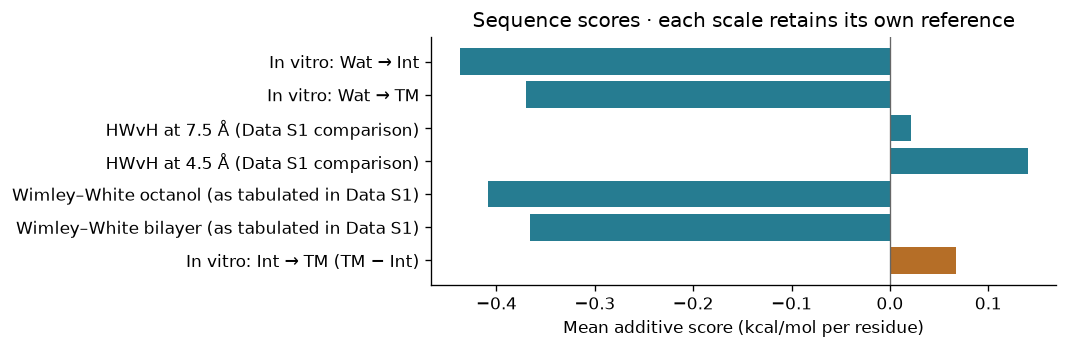

In [5]:
#@title Sequence input and results
sequence_input = "WARYADWLFTDLPLLLLDLLALLV" #@param {type:"string"}
include_comparison_scales = True #@param {type:"boolean"}
sequence_summary = sequence_residues = None
sequence = normalize_sequence(sequence_input)
sequence_summary, sequence_residues = scales.sequence(sequence, include_comparison_scales)
print(f"{len(sequence)} residues: {sequence}")
display(sequence_summary.round(6))
display(sequence_residues.round(6))

available = sequence_summary[sequence_summary.status == "complete"]
sequence_figure, ax = plt.subplots(figsize=(9, max(3, len(available)*0.43)))
colors = ["#267c91" if "int_to_tm" not in k else "#b56e27" for k in available.scale]
ax.barh(available.label, available.mean_kcal_mol, color=colors)
ax.axvline(0, color="0.4", linewidth=0.8)
ax.invert_yaxis()
ax.set(xlabel="Mean additive score (kcal/mol per residue)", title="Sequence scores · each scale retains its own reference")
sequence_figure.tight_layout()
plt.show()

## 3. Optional: calibrated bRc triplet calculation
The example `DLP` is the original bRc triplet. Enter a triplet or the entire **matching bRc scaffold**. This sums only positions 11–13, sets the aqueous-state energy to zero, and normalizes `exp(−ΔG/RT)` over Wat, Int, and TM. These are fitted model estimates for that experimental context. This section is independent of the arbitrary sequence in section 2.

In [6]:
#@title bRc assay-specific prediction
brc_triplet_or_scaffold = "DLP" #@param {type:"string"}
brc_assay = "vitro" #@param ["vitro", "vivo"]
scaffold_result = None
try:
    scaffold_result = scales.scaffold_prediction(brc_triplet_or_scaffold, brc_assay)
    display(scaffold_result.round(6))
except ValueError as exc:
    print(f"Assay prediction unavailable: {exc}")

,state,triplet,delta_g_kcal_mol,model_probability
0,Wat,DLP,0.000000,0.318657
1,Int,DLP,0.095056,0.272113
2,TM,DLP,-0.150597,0.409230


## 4. Load and inspect a PDB
Choose **demo**, **upload** (Colab's file picker), or **path** (a file already in the runtime). Upload exactly one PDB file. The demo is a synthetic, idealized Cα/Cβ helix centered at the origin; it is neither an experimental structure nor a complete all-atom model.

A generic PDB coordinate frame does not identify the membrane. Use a structure already positioned in the bilayer (for example, an OPM-oriented structure), or supply a known center and normal in section 5. The notebook does not position a helix by minimizing its score.

In [7]:
#@title PDB source and chain inventory
pdb_source = "demo" #@param ["demo", "upload", "path"]
pdb_path = "/content/helix.pdb" #@param {type:"string"}
pdb_summary = pdb_residues = coordinates = None
if pdb_source == "demo":
    pdb_text = demo_pdb()
    pdb_input_name = "synthetic_helix.pdb"
elif pdb_source == "upload":
    try:
        from google.colab import files
    except ImportError as exc:
        raise RuntimeError("Use pdb_source='path' outside Colab.") from exc
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Upload exactly one PDB file.")
    pdb_input_name, pdb_bytes = next(iter(uploaded.items()))
    pdb_text = pdb_bytes.decode("utf-8-sig")
elif pdb_source == "path":
    pdb_input_name = Path(pdb_path).name
    pdb_text = Path(pdb_path).read_text(encoding="utf-8-sig")
else:
    raise ValueError("Unknown PDB source")
display(pdb_inventory(pdb_text))

,model_index,pdb_model_serial,chain,first,last,residues,sequence
0,0,0,A,1,24,24,WARYADWLFTDLPLLLLDLLALLV


## 5. Select a helix and define the membrane frame
Select **one continuous helix** by chain and inclusive residue IDs (e.g. `10`, `10A`, `-2`). Empty endpoints use the chain ends. `model_index` is zero-based order in the file; the inventory also shows the PDB MODEL serial. Helicity itself is not inferred.

The paper uses **Cβ**, or **Cα for Gly**, to define each residue's depth:
\[
z_i=(\mathbf r_i-\mathbf c)\cdot\frac{\mathbf n}{\|\mathbf n\|}.
\]
`center_xyz` is a point on the bilayer midplane; the normal points toward **positive z**, with the cytoplasmic side at negative z. The conventional oriented frame is center `0,0,0`, normal `0,0,1`. Signed depths are preserved: the two leaflets are not averaged. The structure is never automatically recentered, tilted, or rescaled to a chosen membrane thickness.

**Exposure:** exposed, buried, and pooled tables are reported separately at the same coordinates. For an isolated peptide, exposed is the natural default interpretation. You can provide a comma-separated label per selected residue to obtain an additional mixed score. Automatic burial assignment is not performed: the paper's assembly-dependent 8 Å alpha-sphere procedure cannot be replaced by an ordinary whole-protein convex hull or inferred reliably from an isolated helix.

**Interpolation:** select one of the three dropdown options below. **Natural cubic splines** (default) pass through all published bin-center energies and have zero second derivative at −39 and +39 Å (`CubicSpline(..., bc_type="natural")`). **Piecewise linear interpolation** connects adjacent bin-center energies with straight lines. **Gaussian/sigmoid fits (to be implemented)** is a placeholder for the original model and raises an explanatory error until available. After changing the dropdown, rerun this cell and the subsequent plotting/export cells.

**Domain:** both implemented interpolation methods use **−39 to +39 Å**. Default out-of-range behavior is an error; spline extrapolation is disabled. Explicit `clip` uses boundary values and marks every affected residue; it does not assume an aqueous zero outside the table. Highest-occupancy alternate atoms are selected (first on ties) and reported. Missing Cβ for a non-Gly residue (or missing Cα for Gly) is always an error; no atom substitution is made. Unknown residues are rejected.

In [8]:
#@title PDB selection and scoring parameters
chain_id = "A" #@param {type:"string"}
start_residue = "" #@param {type:"string"}
end_residue = "" #@param {type:"string"}
model_index = 0 #@param {type:"integer"}
center_xyz = "0,0,0" #@param {type:"string"}
normal_xyz = "0,0,1" #@param {type:"string"}
membrane_frame_confirmed = False #@param {type:"boolean"}
interpolation_method = "Natural cubic splines" #@param ["Natural cubic splines", "Piecewise linear interpolation", "Gaussian/sigmoid fits (to be implemented)"]
out_of_range = "error" #@param ["error", "clip"]
pdb_rt_convention = "workbook" #@param ["workbook", "methods"]
per_residue_exposure = "" #@param {type:"string"}

pdb_summary = pdb_residues = coordinates = None
depth_method = {
    "Natural cubic splines": "spline",
    "Piecewise linear interpolation": "linear",
    "Gaussian/sigmoid fits (to be implemented)": "fitted",
}[interpolation_method]
if depth_method == "fitted" and scales.fitted_model is None:
    raise ValueError("Gaussian/sigmoid fits are not yet implemented. Please select Natural cubic splines or Piecewise linear interpolation.")
if pdb_source != "demo" and not membrane_frame_confirmed:
    raise ValueError("Define/verify the membrane center and normal, then set membrane_frame_confirmed=True.")
center = tuple(float(x.strip()) for x in center_xyz.split(","))
normal = tuple(float(x.strip()) for x in normal_xyz.split(","))
coordinates = pdb_coordinates(pdb_text, chain_id, start_residue, end_residue, model_index)
exposure_labels = [x.strip().lower() for x in per_residue_exposure.split(",")] if per_residue_exposure.strip() else None
pdb_summary, pdb_residues = scales.score_pdb(coordinates, center, normal, depth_method, out_of_range, pdb_rt_convention, exposure_labels)
pdb_sequence = "".join(coordinates.aa)
print(f"Selected {len(coordinates)} residues: {pdb_sequence}")
print(f"Interpolation: {interpolation_method}")
print(f"Signed depth range: {pdb_residues.z_A.min():.3f} to {pdb_residues.z_A.max():.3f} Å")
display(pdb_summary.round(6))
display(pdb_residues.round(6))
print("Depth-independent scores for the SAME PDB-derived sequence:")
pdb_sequence_summary, pdb_sequence_residues = scales.sequence(pdb_sequence, include_comparison_scales)
display(pdb_sequence_summary.round(6))

Selected 24 residues: WARYADWLFTDLPLLLLDLLALLV
Interpolation: Natural cubic splines
Signed depth range: -17.250 to 17.250 Å


,population,n,sum_kcal_mol,mean_kcal_mol,method,rt
0,exposed,24,-7.205365,-0.300224,spline,workbook
1,buried,24,-8.171234,-0.340468,spline,workbook
2,all,24,-8.389935,-0.349581,spline,workbook


,position,model_index,chain,residue_id,resname,aa,depth_atom,altloc,occupancy,x_A,y_A,z_cart_A,exposed_kcal_mol,buried_kcal_mol,all_kcal_mol,z_A,z_used_A,clipped
0,1,0,A,1,TRP,W,CB,,1.0,3.800,0.000,-17.25,-1.419539,-1.042763,-1.229590,-17.25,-17.25,False
1,2,0,A,2,ALA,A,CB,,1.0,-0.660,3.742,-15.75,0.084587,-0.150751,-0.080069,-15.75,-15.75,False
2,3,0,A,3,ARG,R,CB,,1.0,-3.571,-1.300,-14.25,0.014232,0.111934,0.060827,-14.25,-14.25,False
3,4,0,A,4,TYR,Y,CB,,1.0,1.900,-3.291,-12.75,-0.617951,-0.355849,-0.438364,-12.75,-12.75,False
4,5,0,A,5,ALA,A,CB,,1.0,2.911,2.443,-11.25,-0.133637,-0.162740,-0.159246,-11.25,-11.25,False
5,6,0,A,6,ASP,D,CB,,1.0,-2.911,2.443,-9.75,1.974917,1.067856,1.323788,-9.75,-9.75,False
6,7,0,A,7,TRP,W,CB,,1.0,-1.900,-3.291,-8.25,-1.301133,-1.011383,-1.137641,-8.25,-8.25,False
7,8,0,A,8,LEU,L,CB,,1.0,3.571,-1.300,-6.75,-1.074725,-0.870795,-0.949916,-6.75,-6.75,False
8,9,0,A,9,PHE,F,CB,,1.0,0.660,3.742,-5.25,-1.298483,-1.115729,-1.183285,-5.25,-5.25,False
9,10,0,A,10,THR,T,CB,,1.0,-3.800,0.000,-3.75,0.331099,0.002597,0.097331,-3.75,-3.75,False


Depth-independent scores for the SAME PDB-derived sequence:


,scale,label,n,sum_kcal_mol,mean_kcal_mol,approx_sum_se,missing_aa,status
0,vitro_int,In vitro: Wat → Int,24,-10.497343,-0.437389,0.273020,,complete
1,vitro_tm,In vitro: Wat → TM,24,-8.876435,-0.369851,0.289262,,complete
2,vivo_int,In vivo: Wat → Int,24,NaN,NaN,NaN,"A,R",unavailable (missing coefficients)
3,vivo_tm,In vivo: Wat → TM,24,NaN,NaN,NaN,"A,R",unavailable (missing coefficients)
4,hwvh_7_5,HWvH at 7.5 Å (Data S1 comparison),24,0.510000,0.021250,NaN,,complete
5,hwvh_4_5,HWvH at 4.5 Å (Data S1 comparison),24,3.360000,0.140000,NaN,,complete
6,ww_octanol,Wimley–White octanol (as tabulated in Data S1),24,-9.798619,-0.408276,NaN,,complete
7,ww_bilayer,Wimley–White bilayer (as tabulated in Data S1),24,-8.788568,-0.366190,NaN,,complete
8,vitro_int_to_tm,In vitro: Int → TM (TM − Int),24,1.620908,0.067538,NaN,,complete
9,vivo_int_to_tm,In vivo: Int → TM (TM − Int),24,NaN,NaN,NaN,"A,R",unavailable (missing coefficients)


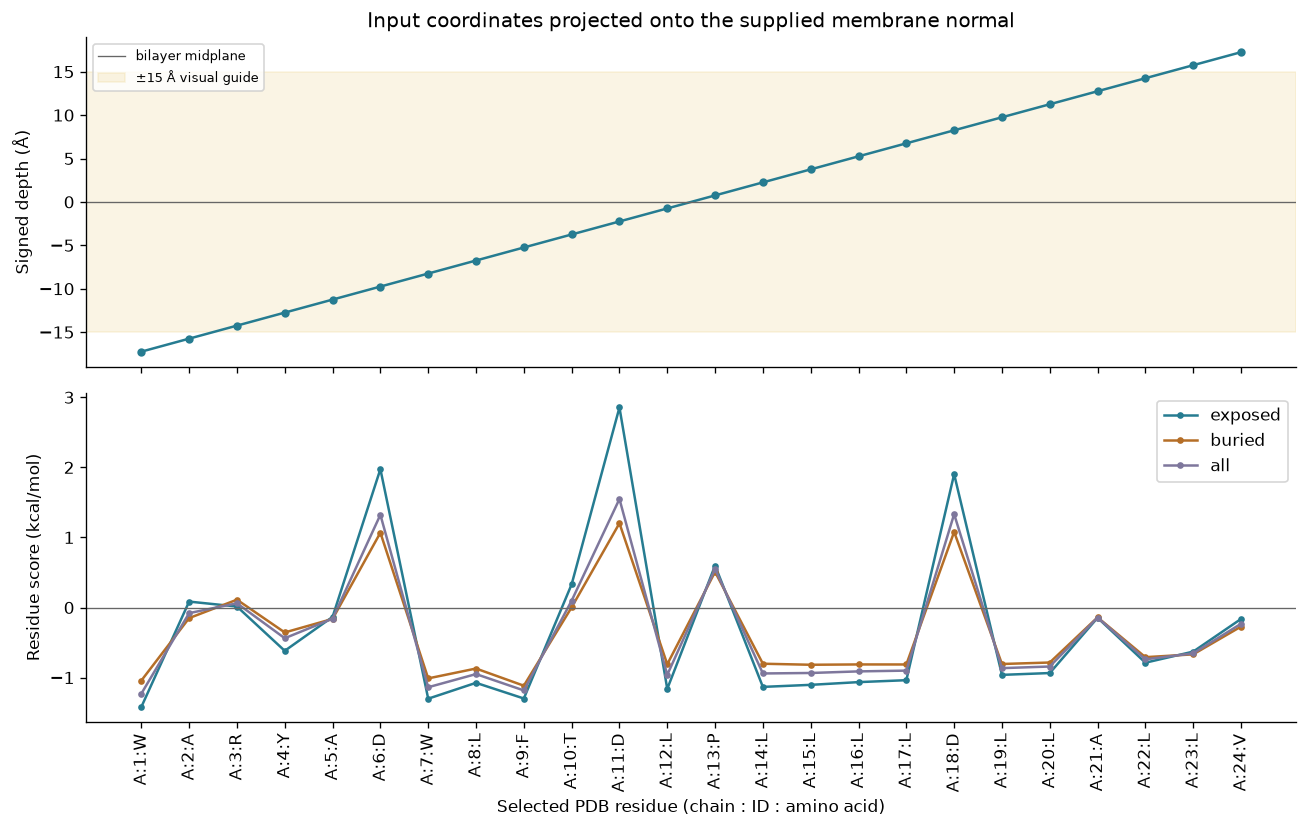

In [9]:
#@title Inspect coordinates and per-residue scores
if pdb_residues is None:
    raise RuntimeError("Run PDB scoring successfully first.")
pdb_figure, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
positions = pdb_residues.position
axes[0].plot(positions, pdb_residues.z_A, "o-", color="#267c91", markersize=4)
axes[0].axhline(0, color="0.4", linewidth=0.8, label="bilayer midplane")
axes[0].axhspan(-15, 15, color="#e8c76a", alpha=0.18, label="±15 Å visual guide")
axes[0].set(ylabel="Signed depth (Å)", title="Input coordinates projected onto the supplied membrane normal")
axes[0].legend(fontsize=8)
for population, color in [("exposed", "#267c91"), ("buried", "#b56e27"), ("all", "#7e779c")]:
    axes[1].plot(positions, pdb_residues[f"{population}_kcal_mol"], "o-", label=population, color=color, markersize=3)
if "selected_kcal_mol" in pdb_residues:
    axes[1].plot(positions, pdb_residues.selected_kcal_mol, "k--", label="user labels")
axes[1].axhline(0, color="0.4", linewidth=0.8)
axes[1].set(ylabel="Residue score (kcal/mol)", xlabel="Selected PDB residue (chain : ID : amino acid)")
if len(positions) <= 60:
    axes[1].set_xticks(positions, [f"{r.chain}:{r.residue_id}:{r.aa}" for r in pdb_residues.itertuples()], rotation=90)
axes[1].legend()
pdb_figure.tight_layout()
plt.show()

## 6. Inspect the underlying depth profiles
Dots are the published bin-center energies; curves use the **same interpolation selection as PDB scoring** in section 5, evaluated on a dense depth grid. The selected RT convention applies to both dots and curves. The spline and linear curves are not the sigmoid/Gaussian fits shown in Fig. 3.

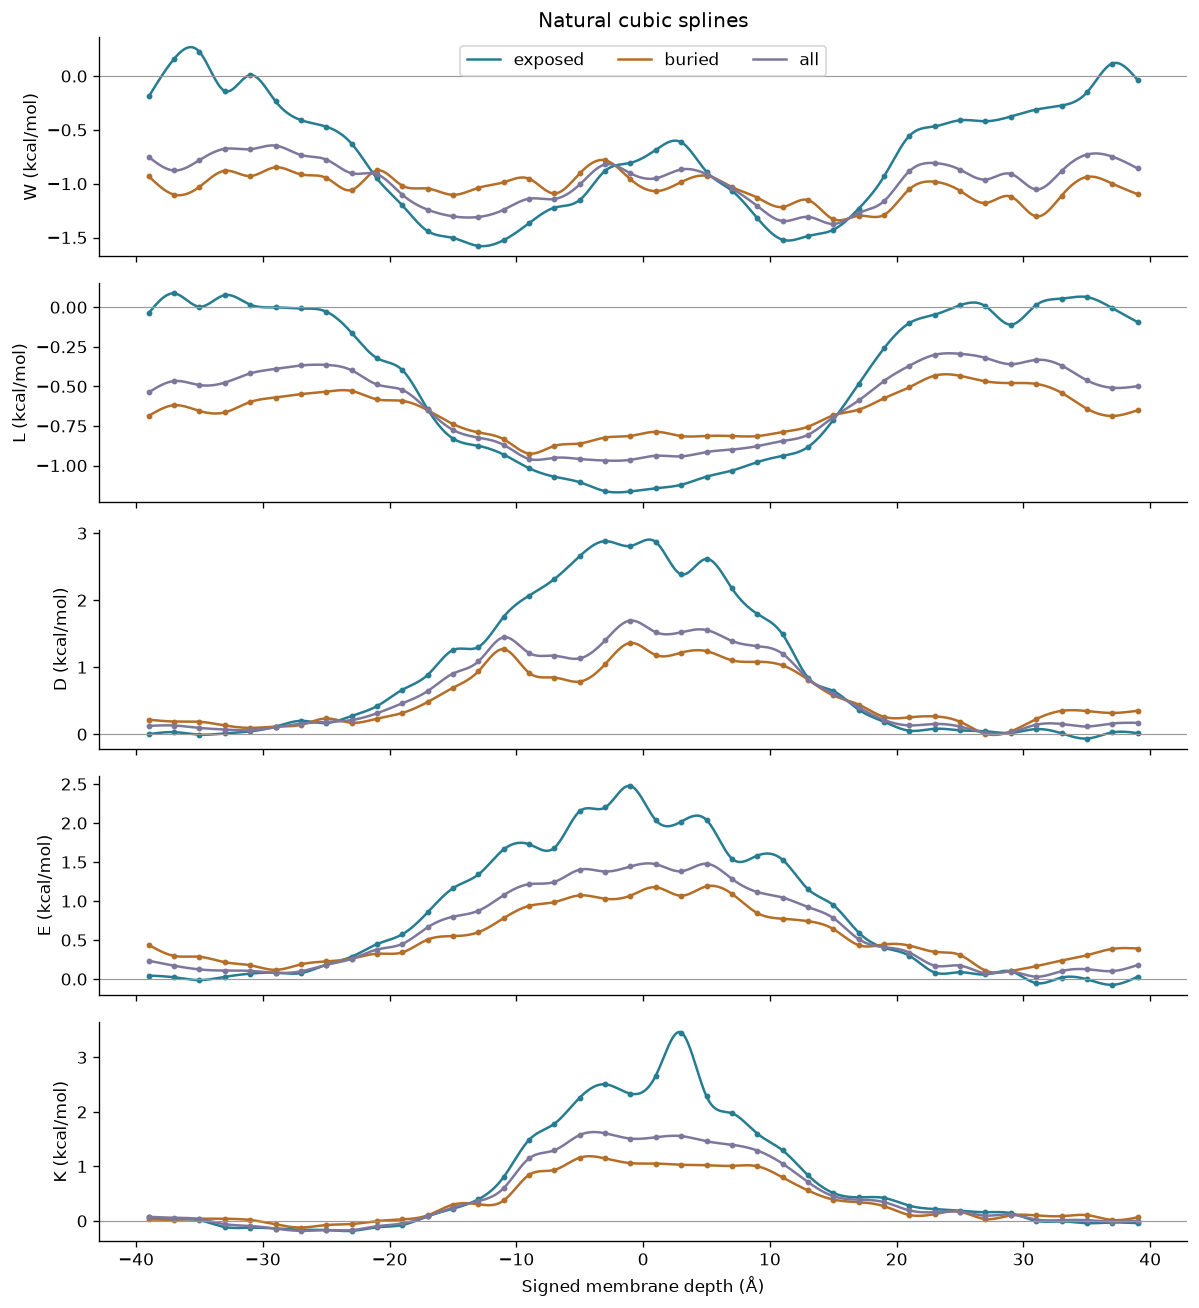

In [10]:
#@title Depth profile viewer
profile_amino_acids = "WLDEK" #@param {type:"string"}
if pdb_residues is None:
    raise RuntimeError("Run PDB scoring successfully with the chosen interpolation method first.")
profile_aas = list(dict.fromkeys(normalize_sequence(profile_amino_acids)))
profile_figure, axes = plt.subplots(len(profile_aas), 1, figsize=(10, max(3, 2.2*len(profile_aas))), sharex=True, squeeze=False)
for aa, ax in zip(profile_aas, axes[:, 0]):
    for population, color in [("exposed", "#267c91"), ("buried", "#b56e27"), ("all", "#7e779c")]:
        grid = DATA["depth_scales"][population]["z"]
        dense_z = np.linspace(grid[0], grid[-1], 781)
        profile = scales.depth(aa*len(dense_z), dense_z, population, method=depth_method, rt=pdb_rt_convention)
        published = scales.depth(aa*len(grid), grid, population, method="linear", rt=pdb_rt_convention)
        ax.plot(dense_z, profile.energy_kcal_mol, label=population, color=color)
        ax.plot(grid, published.energy_kcal_mol, "o", markersize=2.5, color=color)
    ax.axhline(0, color="0.6", linewidth=0.7)
    ax.set(ylabel=f"{aa} (kcal/mol)")
axes[0, 0].legend(ncol=3)
axes[0, 0].set_title(interpolation_method)
axes[-1, 0].set_xlabel("Signed membrane depth (Å)")
profile_figure.tight_layout()
plt.show()

## 7. Export results and reproducibility information
The ZIP contains CSV results (blank numeric values mean unavailable), PNG/SVG figures, all scale coefficients, and a JSON manifest with inputs, coordinate conventions, versions, and source hashes. Full uploaded PDB contents are not included; selected coordinates are in the residue table. Download is optional, so **Run all** completes without opening a download dialog.

In [11]:
#@title Save results (optionally download in Colab)
download_results = False #@param {type:"boolean"}
if sequence_summary is None or pdb_summary is None:
    raise RuntimeError("Run the sequence and PDB scoring cells successfully before exporting.")
output_dir = Path("membrane_scale_results")
output_dir.mkdir(exist_ok=True)
exported = []
tables = {"sequence_summary": sequence_summary, "sequence_residues": sequence_residues,
          "pdb_summary": pdb_summary, "pdb_residues": pdb_residues,
          "pdb_sequence_summary": pdb_sequence_summary, "pdb_sequence_residues": pdb_sequence_residues}
if scaffold_result is not None:
    tables["brc_scaffold_prediction"] = scaffold_result
for name, table in tables.items():
    path = output_dir / f"{name}.csv"
    table.to_csv(path, index=False)
    exported.append(path)
for name, figure in [("sequence", sequence_figure), ("pdb", pdb_figure), ("depth_profiles", profile_figure)]:
    for extension in ("png", "svg"):
        path = output_dir / f"{name}.{extension}"
        figure.savefig(path, bbox_inches="tight", dpi=180)
        exported.append(path)
manifest = {
    "citation": DATA["citation"], "doi": DATA["doi"], "workbook_sha256": DATA["workbook_sha256"],
    "sequence": sequence, "include_comparison_scales": include_comparison_scales,
    "brc_input": brc_triplet_or_scaffold, "brc_assay": brc_assay,
    "pdb_input_name": pdb_input_name, "pdb_source": pdb_source,
    "pdb_text_sha256": hashlib.sha256(pdb_text.encode("utf-8")).hexdigest(),
    "chain_id": chain_id, "start_residue": start_residue, "end_residue": end_residue,
    "model_index": model_index, "selected_sequence": pdb_sequence,
    "center_xyz_A": center, "positive_membrane_normal": normal,
    "membrane_frame_confirmed": membrane_frame_confirmed or pdb_source == "demo",
    "depth_method": depth_method, "out_of_range": out_of_range, "pdb_rt_convention": pdb_rt_convention,
    "interpolation_method": interpolation_method,
    "pdb_rt_kcal_mol": DATA["pdb_rt_" + pdb_rt_convention],
    "depth_atoms": "CB for non-Gly; CA for Gly; missing atoms are errors", "exposure_labels": exposure_labels,
    "original_fitted_model_loaded": ORIGINAL_FITTED_MODEL is not None,
    "units": {"energy": "kcal/mol", "coordinates": "angstrom"},
    "notes": DATA["notes"], "python": platform.python_version(),
    "packages": {p: importlib.metadata.version(p) for p in ("numpy", "pandas", "matplotlib", "biopython", "scipy")}
}
for name, value in [("manifest.json", manifest), ("scales.json", DATA)]:
    path = output_dir / name
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False))
    exported.append(path)
archive_path = Path("membrane_scale_results.zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in exported:
        archive.write(path, path.name)
print(f"Wrote {len(exported)} files to {archive_path.resolve()}")
if download_results:
    try:
        from google.colab import files
    except ImportError:
        print("Outside Colab: open the ZIP at the path above.")
    else:
        files.download(str(archive_path))

Wrote 15 files to membrane_scale_results.zip


### Provenance and scope
Source: Grau B., Kormos R., Bañó-Polo M., et al. *Sequence-dependent scale for translocon-mediated insertion of interfacial helices in membranes.* Science Advances **11**, eads6804 (2025), [doi:10.1126/sciadv.ads6804](https://doi.org/10.1126/sciadv.ads6804). Experimental coefficients: Data S1, `∆Gapp Per Residue!B3:M22`; PDB potentials: `∆G PDB!AW3:BR42`, `AW46:BR85`, `AW89:BR128`. PDB aqueous references use exposed propensities at bin centers −39, −37, −35, +35, +37, +39 Å for all three populations.

The notebook's additions are explicit interpolation, PDB input handling, additive whole-segment scores, and plotting/export. It does not reproduce UMAP embeddings, fit new experimental coefficients, infer helicity, assign a membrane orientation, or implement the original assembly burial classifier. No protonation, termini, helix-length, or hydrophobic-moment correction is added to the published coefficients. The article and supplied data are attributed to their authors and distributed under the article's [CC BY-NC 4.0 license](https://creativecommons.org/licenses/by-nc/4.0/).